# Разведочный анализ данных (EDA): Hotel Booking Demand
**Цель этапа:** Получить интуицию о данных, выявить аномалии, пропуски, изучить взаимосвязи признаков с целевой переменной и выявить потенциальные утечки данных (Data Leakage) перед построением ML-моделей.

**Датасет:** Hotel Booking Demand (TidyTuesday), бронирования двух португальских отелей (2015–2017 гг.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Настройка стиля графиков
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
pd.set_option("styler.format.precision", 3)

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv")
print(f"Размер датасета: {df.shape}")
display(df.head(3))

Размер датасета: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


# Структурная информация датасета

In [4]:
print("Типы данных признаков \n")
df.info()

Типы данных признаков 

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  mea

In [5]:
describe_df = df.describe(include='all').T
display(describe_df.style.set_caption("Таблица 1: Описательные статистики всех признаков датасета"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,nan,nan,nan,nan,nan,nan,nan
is_canceled,119390.000,nan,nan,nan,0.370,0.483,0.000,0.000,0.000,1.000,1.000
lead_time,119390.000,nan,nan,nan,104.011,106.863,0.000,18.000,69.000,160.000,737.000
arrival_date_year,119390.000,nan,nan,nan,2016.157,0.707,2015.000,2016.000,2016.000,2017.000,2017.000
arrival_date_month,119390,12,August,13877,nan,nan,nan,nan,nan,nan,nan
arrival_date_week_number,119390.000,nan,nan,nan,27.165,13.605,1.000,16.000,28.000,38.000,53.000
arrival_date_day_of_month,119390.000,nan,nan,nan,15.798,8.781,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,119390.000,nan,nan,nan,0.928,0.999,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,119390.000,nan,nan,nan,2.500,1.908,0.000,1.000,2.000,3.000,50.000
adults,119390.000,nan,nan,nan,1.856,0.579,0.000,2.000,2.000,2.000,55.000


## Описание признаков

Датасет содержит 32 столбца: одну целевую переменную и 31 характеристику брони.

**Целевая переменная**

* `is_canceled` - бронь отменена или гость не явился (1), гость заехал (0)

**Параметры брони**

* `hotel` - тип отеля: City Hotel (городской) или Resort Hotel (курортный)
* `lead_time` - число дней между оформлением брони и датой заезда
* `arrival_date_year` - год заезда
* `arrival_date_month` - месяц заезда, название на английском
* `arrival_date_week_number` - номер недели заезда в году
* `arrival_date_day_of_month` - день месяца заезда
* `stays_in_weekend_nights` - число ночей в выходные, субботу и воскресенье
* `stays_in_week_nights` - число ночей в будни, с понедельника по пятницу
* `reserved_room_type` - тип забронированного номера, код обезличен
* `assigned_room_type` - тип фактически предоставленного номера, может отличаться от забронированного
* `meal` - тип питания: BB (завтрак), HB (полупансион), FB (полный пансион), SC (без питания), Undefined (не указано)
* `adr` - средняя цена за ночь: сумма транзакций по размещению, делённая на число ночей. Стоимость брони целиком равна `adr`, умноженной на длительность
* `deposit_type` - тип депозита: No Deposit (без предоплаты), Non Refund (невозвратный), Refundable (возвратный)
* `days_in_waiting_list` - сколько дней бронь находилась в листе ожидания до подтверждения гостю
* `required_car_parking_spaces` - число запрошенных парковочных мест
* `total_of_special_requests` - число специальных пожеланий: высокий этаж, детская кроватка и тому подобное
* `booking_changes` - число изменений, внесённых в бронь после оформления

**Состав гостей**

* `adults` - число взрослых
* `children` - число детей
* `babies` - число младенцев
* `country` - страна гостя, код по ISO 3166-1 alpha-3

**Канал продаж**

* `market_segment` - сегмент рынка: Online TA, Offline TA/TO, Groups, Direct, Corporate, Complementary, Aviation. TA означает турагентство, TO - туроператора
* `distribution_channel` - канал дистрибуции: TA/TO, Direct, Corporate, GDS
* `customer_type` - тип клиента: Transient (разовая бронь), Transient-party (разовая в составе группы), Contract (по договору), Group (групповая)
* `agent` - идентификатор турагентства, оформившего бронь
* `company` - идентификатор компании-заказчика или плательщика

**История гостя**

* `is_repeated_guest` - гость уже останавливался в отеле (1) или нет (0)
* `previous_cancellations` - число прошлых броней этого гостя, которые он отменил
* `previous_bookings_not_canceled` - число прошлых броней, завершившихся заездом

**Исход брони**

* `reservation_status` - итоговый статус: Check-Out (гость заехал и выехал), Canceled (отменена), No-Show (гость не явился)
* `reservation_status_date` - дата установки последнего статуса

Два последних столбца описывают то, что произошло после оформления брони, а не в момент её создания. Такие признаки разбираются отдельно в разделе про утечки данных.


## Анализ дубликатов

В этом разделе полными повторами называются строки, совпадающие по всем 32 исходным столбцам, включая целевую переменную и итоговый статус бронирования.

Полное совпадение доступных полей не доказывает, что записи относятся к одной брони. В данных нет идентификатора бронирования или групповой заявки, позволяющего отличить технические повторы от самостоятельных броней с одинаковыми параметрами.

Поэтому сначала оцениваем масштаб и распределение повторов, затем сравниваем показатели при сохранении всех строк и при удалении полных повторов. Такое сравнение рассматривается как анализ чувствительности, а не как доказательство необходимости удаления.

In [6]:
# Повторы по всем исходным столбцам; df не изменяется.
duplicates_mask = df.duplicated(keep="first")

print(f"Всего строк: {len(df):,}")
print(
    f"Повторных строк сверх первого экземпляра: "
    f"{duplicates_mask.sum():,} ({duplicates_mask.mean():.2%})"
)
print(
    f"Всех строк в повторяющихся группах: "
    f"{df.duplicated(keep=False).sum():,}"
)
print(
    f"Уникальных комбинаций значений: "
    f"{len(df) - duplicates_mask.sum():,}"
)

Всего строк: 119,390
Повторных строк сверх первого экземпляра: 31,994 (26.80%)
Всех строк в повторяющихся группах: 40,165
Уникальных комбинаций значений: 87,396


Более четверти строк являются повторными экземплярами уже встречавшихся комбинаций значений. Их происхождение по одному факту совпадения определить нельзя.

In [7]:
# Размеры групп одинаковых строк
group_sizes = df.value_counts(dropna=False)

print(f"Уникальных наборов значений: {len(group_sizes)}")
print(f"Максимальная группа: {group_sizes.max()} одинаковых строк\n")

sizes = (group_sizes.value_counts()
         .sort_index()
         .head(15)
         .rename_axis("Копий строки")
         .rename("Таких наборов")
         .reset_index())

print(sizes.to_string(index=False))

Уникальных наборов значений: 87396
Максимальная группа: 180 одинаковых строк

 Копий строки  Таких наборов
            1          79225
            2           5034
            3            969
            4            497
            5            275
            6            171
            7            115
            8            103
            9             93
           10            123
           11             60
           12             47
           13             36
           14             36
           15             64


Встречаются не только пары, но и крупные группы полностью одинаковых строк. Сам размер группы не позволяет установить причину совпадений: возможны как особенности выгрузки данных, так и одинаковые параметры нескольких самостоятельных броней.

In [8]:
top_set = pd.Series(group_sizes.idxmax(), index=df.columns)

show_cols = ["hotel", "market_segment", "distribution_channel",
             "arrival_date_year", "arrival_date_month", "arrival_date_day_of_month",
             "lead_time", "adults", "adr", "deposit_type",
             "reservation_status", "reservation_status_date", "is_canceled"]

print(f"Набор, повторяющийся {group_sizes.max()} раз:\n")
print(top_set[show_cols].to_string())

Набор, повторяющийся 180 раз:

hotel                        City Hotel
market_segment                   Groups
distribution_channel              TA/TO
arrival_date_year                  2016
arrival_date_month             November
arrival_date_day_of_month             7
lead_time                           277
adults                                2
adr                               100.0
deposit_type                 Non Refund
reservation_status             Canceled
reservation_status_date      2016-04-04
is_canceled                           1


Максимальная группа содержит 180 строк с одинаковыми значениями всех исходных полей. Сегмент Groups и совпадающие параметры согласуются с гипотезой о связанном групповом бронировании, но не подтверждают её.

Без идентификатора заявки нельзя установить, соответствуют ли эти строки одной заявке на несколько номеров, нескольким самостоятельным броням или техническому повторению записей.

In [9]:
# Распределение дубликатов по сегментам рынка
segments = pd.DataFrame({
    "Строк в файле": df["market_segment"].value_counts(),
    "Из них копий": df.loc[duplicates_mask, "market_segment"].value_counts(),
}).fillna(0).astype(int)

segments["Останется"] = segments["Строк в файле"] - segments["Из них копий"]
segments["Доля копий в сегменте"] = (segments["Из них копий"] / segments["Строк в файле"])
segments["Вклад в общее число копий"] = (segments["Из них копий"] / duplicates_mask.sum())

display(segments.sort_values("Из них копий", ascending=False)
        .style.format({
            "Доля копий в сегменте": "{:.1%}",
            "Вклад в общее число копий": "{:.1%}",
        })
        .set_caption("Таблица 2: Дубликаты по сегментам рынка"))

,Строк в файле,Из них копий,Останется,Доля копий в сегменте,Вклад в общее число копий
market_segment,,,,,
Groups,19811,14869,4942,75.1%,46.5%
Offline TA/TO,24219,10330,13889,42.7%,32.3%
Online TA,56477,4859,51618,8.6%,15.2%
Corporate,5295,1083,4212,20.5%,3.4%
Direct,12606,802,11804,6.4%,2.5%
Complementary,743,41,702,5.5%,0.1%
Aviation,237,10,227,4.2%,0.0%
Undefined,2,0,2,0.0%,0.0%


"Доля копий в сегменте" показывает долю строк, которые были бы удалены при сохранении первого экземпляра каждой уникальной комбинации значений. "Вклад в общее число копий" показывает распределение таких удалений между сегментами.

В Groups удаление затронуло бы 75.1% строк. На Groups и Offline TA/TO вместе приходится 78.8% повторных строк сверх первого экземпляра.
Таким образом, повторы распределены по сегментам неравномерно.

Это наблюдение показывает, что дедупликация изменяет структуру выборки, но не позволяет установить происхождение повторов.

In [10]:
# Анализ чувствительности до обработки пропусков и создания признаков.
# Основной df не изменяется.

def compare_duplicate_scenarios(data):
    if "rooms_in_booking" in data.columns:
        raise ValueError(
            "Перезапустите ядро и выполните исправленный ноутбук с начала: "
            "rooms_in_booking не должен создаваться."
        )

    dedup = data.drop_duplicates()

    def cancellation_stats(target):
        n = len(target)
        k = int(target.sum())

        if n == 0:
            return n, k, np.nan, np.nan, np.nan

        p = k / n
        z = 1.96
        denominator = 1 + z**2 / n
        center = (p + z**2 / (2 * n)) / denominator
        half_width = (
            z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
            / denominator
        )

        return n, k, p, center - half_width, center + half_width

    rows = []

    for scenario, current in [
        ("Все строки сохранены", data),
        ("Полные повторы удалены", dedup),
    ]:
        groups = {
            "Весь набор": current["is_canceled"],
            "Non Refund": current.loc[
                current["deposit_type"].eq("Non Refund"), "is_canceled"
            ],
            "Groups": current.loc[
                current["market_segment"].eq("Groups"), "is_canceled"
            ],
            "City Hotel": current.loc[
                current["hotel"].eq("City Hotel"), "is_canceled"
            ],
        }

        for group, target in groups.items():
            n, k, p, low, high = cancellation_stats(target)

            rows.append({
                "Сценарий": scenario,
                "Группа": group,
                "Строк": n,
                "Отмен": k,
                "Доля группы в наборе": n / len(current),
                "Доля отмен": p,
                "Нижняя граница 95% ДИ": low,
                "Верхняя граница 95% ДИ": high,
            })

    rates = pd.DataFrame(rows).set_index(["Сценарий", "Группа"])

    correlations = pd.DataFrame({
        "Все строки сохранены": [
            data["adr"].corr(data["is_canceled"]),
            data["lead_time"].corr(data["is_canceled"]),
        ],
        "Полные повторы удалены": [
            dedup["adr"].corr(dedup["is_canceled"]),
            dedup["lead_time"].corr(dedup["is_canceled"]),
        ],
    }, index=[
        "Корреляция adr с is_canceled",
        "Корреляция lead_time с is_canceled",
    ])

    print("Этап: исходные данные, до обработки пропусков и выбросов.")
    print(f"Всего строк: {len(data):,}")
    print(
        f"При дедупликации было бы удалено: "
        f"{len(data) - len(dedup):,} "
        f"({1 - len(dedup) / len(data):.2%})"
    )

    display(
        rates.style.format({
            "Строк": "{:,.0f}",
            "Отмен": "{:,.0f}",
            "Доля группы в наборе": "{:.2%}",
            "Доля отмен": "{:.2%}",
            "Нижняя граница 95% ДИ": "{:.2%}",
            "Верхняя граница 95% ДИ": "{:.2%}",
        }).set_caption(
            "Таблица 3а. Чувствительность долей отмен "
            "к удалению полных повторов"
        )
    )

    display(
        correlations.style.format("{:.3f}").set_caption(
            "Таблица 3б. Чувствительность корреляций "
            "к удалению полных повторов"
        )
    )


compare_duplicate_scenarios(df)

Этап: исходные данные, до обработки пропусков и выбросов.
Всего строк: 119,390
При дедупликации было бы удалено: 31,994 (26.80%)


,Все строки сохранены,Полные повторы удалены
Корреляция adr с is_canceled,0.048,0.128
Корреляция lead_time с is_canceled,0.293,0.185


Интервалы Вильсона рассчитаны при допущении независимости наблюдений. Если одинаковые строки связаны общей заявкой либо являются техническими повторами, это допущение может нарушаться. Поэтому интервалы показывают неопределённость долей в рамках принятой модели, но не учитывают неизвестную природу повторов.

Два сценария используют пересекающиеся наблюдения. Сравнение является анализом чувствительности, а не сравнением двух независимых выборок.

### Решение по полным повторам

Все строки сохраняются в основном `df`. Полное совпадение доступных полей не позволяет отличить технические повторы от самостоятельных броней с одинаковыми параметрами. Сравнение с вариантом `drop_duplicates()` служит анализом чувствительности и не изменяет основной набор.

### Доступность rooms_in_booking

`rooms_in_booking` не входит в набор признаков: доступные поля не позволяют определить число номеров в заявке независимо от её исхода.

Для получения признака необходим источник, содержащий число номеров именно на момент подтверждения брони: поле заявки либо история её состава с идентификаторами заявки, номерных позиций и временем изменений.

Одного идентификатора групповой заявки недостаточно. Подсчёт строк по нему допустим только при подтверждении, что каждая строка соответствует одному номеру, технические повторы отсутствуют, а состав заявки соответствует моменту прогноза. Группировка по итоговым статусам и целевой переменной для получения признака недопустима.

Сохранение всех строк не подтверждает отсутствие технических повторов. Это решение принято в условиях недостаточной информации об их происхождении. Анализ чувствительности описательных показателей не устанавливает устойчивость качества моделей к дедупликации.

### Выводы по дубликатам

В исходных данных 119 390 строк и 87 396 уникальных комбинаций значений всех 32 исходных столбцов. При сохранении первого экземпляра каждой комбинации было бы удалено 31 994 строки, или 26.80%. Это число повторных экземпляров, а не всех строк в повторяющихся группах.

На Groups и Offline TA/TO приходится 78.8% повторных экземпляров. Максимальная группа содержит 180 одинаковых строк. Ни размер группы, ни сегмент не доказывают, что строки относятся к одной заявке на несколько номеров.

Анализ чувствительности показывает изменение общей доли отмен с 37.0% до 27.5%, а в Groups — с 61.1% до 27.0% при удалении полных повторов. Число строк Non Refund сокращается с 14 587 до 1 038; доля этой категории в наборе меняется примерно с 12.2% до 1.2%. Эти проценты описывают распространённость категории, а не долю отмен внутри неё.

Корреляция adr с is_canceled меняется с 0.048 до 0.128, а корреляция lead_time — с 0.293 до 0.185. Знаки сохраняются, но величины чувствительны к решению о повторах. Различия не доказывают корректность удаления и не позволяют объявить связи в полном наборе артефактом.

Основной df сохраняет все строки. Без идентификатора бронирования невозможно обоснованно отделить технические повторы от самостоятельных броней. Сохранение возможных технических повторов также может влиять на результаты; по текущим полям устранить эту неопределённость нельзя.

rooms_in_booking не включается в анализ и моделирование. Для его получения необходим независимый источник числа номеров в заявке на момент подтверждения брони.

## Анализ и обработка пропусков

In [11]:
# Пропуски по признакам
na_counts = df.isna().sum()
na_counts = na_counts[na_counts > 0].sort_values(ascending=False)

missing_stats = pd.DataFrame({
    "Пропусков": na_counts,
    "Доля от строк, %": (na_counts / len(df) * 100).round(3),
    "Доля от всех пропусков, %": (na_counts / na_counts.sum() * 100).round(1),
})
display(missing_stats.style.set_caption("Таблица 4: Пропуски по признакам"))

print(f"Общая разреженность:   {df.isna().sum().sum() / df.size:.2%}")
print(f"Без столбца company:   {df.drop(columns='company').isna().sum().sum() / df.drop(columns='company').size:.2%}")
print(f"Строк ровно с одним пропуском: {(df.isna().sum(axis=1) == 1).mean():.1%}")

,Пропусков,"Доля от строк, %","Доля от всех пропусков, %"
company,112593,94.307,87.000
agent,16340,13.686,12.600
country,488,0.409,0.400
children,4,0.003,0.000


Общая разреженность:   3.39%
Без столбца company:   0.45%
Строк ровно с одним пропуском: 91.4%


In [12]:
# Гипотеза: agent не указан там, где турагента нет
agent_missing = df["agent"].isna()

print("Доля пропусков agent внутри канала продаж:\n")
print(df.assign(na=agent_missing)
        .groupby("distribution_channel")["na"]
        .agg(Броней="size", Доля_пропусков="mean").round(3).to_string())

print("\nСтруктура каналов по годам (доля броней):")
print(pd.crosstab(df["arrival_date_year"], df["distribution_channel"], normalize="index").round(3).to_string())

Доля пропусков agent внутри канала продаж:

                      Броней  Доля_пропусков
distribution_channel                        
Corporate               6677           0.830
Direct                 14645           0.521
GDS                      193           0.010
TA/TO                  97870           0.032
Undefined                  5           0.600

Структура каналов по годам (доля броней):
distribution_channel  Corporate  Direct    GDS  TA/TO  Undefined
arrival_date_year                                               
2015                      0.067   0.127  0.000  0.807        0.0
2016                      0.058   0.120  0.002  0.820        0.0
2017                      0.047   0.124  0.002  0.826        0.0


In [13]:
# Связь самого факта пропуска с целевой переменной
na_link = pd.DataFrame([
    {
        "Признак": col,
        "Доля отмен при пропуске": round(df.loc[df[col].isna(), "is_canceled"].mean(), 3),
        "Доля отмен при заполненном": round(df.loc[df[col].notna(), "is_canceled"].mean(), 3),
    }
    for col in na_counts.index
]).set_index("Признак")

display(na_link.style.set_caption("Таблица 5: Связь факта пропуска с отменой"))
print(f"Доля отмен в среднем по данным: {df['is_canceled'].mean():.3f}")

,Доля отмен при пропуске,Доля отмен при заполненном
Признак,,
company,0.382,0.175
agent,0.247,0.390
country,0.137,0.371
children,1.000,0.370


Доля отмен в среднем по данным: 0.370


Пропуск сам по себе предиктивен, причём сильно. Брони без указанной страны отменяются в 7.5% случаев против 27.6% у остальных, то есть почти вчетверо реже среднего. Отсюда следует, что заполнять модой нельзя.

### Решения по пропускам

Пропуски возникают по разным причинам, и от причины зависит способ обработки.

Пропуски в `agent` зависят от канала продаж: 86.1% для корпоративных броней, 51.0% для прямых и лишь 1.7% для броней через турагентства. У корпоративной или прямой брони турагента просто нет, то есть пропуск объясняется другим столбцом. Общая доля пропусков снижается по годам с 17.6% до 12.0%, но это следствие сдвига структуры каналов в сторону турагентств, а не изменения в правилах заполнения.

Пропуск `country` ведёт себя иначе: такие брони отменяются в 7.5% случаев против 27.6% у остальных. Здесь пропуск отличает группу броней сам по себе, то есть несёт информацию об отмене, и терять её нельзя.

Разница определяет решение. Там, где пропуск - следствие другого признака, достаточно нейтральной метки. Там, где пропуск сам является сигналом, его нужно сохранить как отдельную категорию, а не затирать подстановкой.

| Столбец | Пропусков | Решение | Обоснование |
|---|---|---|---|
| `children` | 4 (0.005%) | заполнить нулём, привести к `int` | четыре строки на 87 тысяч; тип `float` возник только из-за пропусков |
| `country` | 452 (0.52%) | отдельная категория `Unknown` | пропуск несёт информацию об отмене: 7.5% против 27.6%. Заполнение модой `PRT` (35.7% отмен) внесло бы сигнал противоположного знака |
| `agent` | 12 193 (13.95%) | отдельная категория `No agent` | смысл пропуска - бронь без турагента; канал продаж уже закодирован в `distribution_channel` |
| `company` | 82 137 (93.98%) | бинарный `has_company`, столбец удалить | при 94% пропусков учиться по конкретным ID невозможно, но факт корпоративной брони значим: 10.9% отмен против 28.6% |

In [14]:
# Обработка пропусков

if "company" in df.columns:
    agent_missing = df["agent"].isna()          # запоминаем до заполнения

    df["children"] = df["children"].fillna(0).astype(int)
    df["country"] = df["country"].fillna("Unknown")
    df["agent"] = df["agent"].astype("Int64").astype(str)
    df.loc[agent_missing, "agent"] = "No agent"
    df["has_company"] = df["company"].notna().astype(int)
    df = df.drop(columns="company")
else:
    print("Пропуски уже обработаны, повторный запуск пропущен\n")

print(f"Пропусков осталось: {df.isna().sum().sum()}")
print(f"Размер датасета:    {df.shape[0]:,} строк x {df.shape[1]} столбцов")
print(f"Тип agent: {df['agent'].dtype}, примеры: {df['agent'].unique()[:4].tolist()}\n")

print("Проверка нового признака has_company:")
print(df.groupby("has_company")["is_canceled"]
        .agg(Броней="size", Доля_отмен="mean").round(3).to_string())

Пропусков осталось: 0
Размер датасета:    119,390 строк x 32 столбцов
Тип agent: str, примеры: ['No agent', '304', '240', '303']

Проверка нового признака has_company:
             Броней  Доля_отмен
has_company                    
0            112593       0.382
1              6797       0.175


### Результат обработки пропусков

Пропуски устранены во всех четырёх столбцах, итоговый размер данных - 87 396 строк и 33 столбца.

**Типизация категориальных признаков.** Столбцы `agent` и `country` приведены к строковому типу и содержат явную категорию для пропуска: `No agent` и `Unknown` соответственно. Числовые значения `agent` являются идентификаторами, а не количественной величиной: порядок и арифметические операции для них не определены. Приведение к строке фиксирует это на уровне типа данных и исключает попадание признака в расчёты, предполагающие числовую шкалу, в том числе в корреляционную матрицу.

**Новый признак.** Столбец `company` заменён бинарным `has_company`. Доля отмен при наличии компании-заказчика составляет 10.9% против 28.6% в остальных бронях.

**Применение на следующем этапе.** `agent` и `country` передаются в модель как категориальные признаки без дополнительного кодирования, категория пропуска сохраняется наравне с прочими значениями. `has_company` включается в набор признаков как самостоятельный предиктор.

## Итог предобработки

In [64]:
# Состояние основного набора после обработки пропусков.
# Полные повторы сохранены; очистка аномалий выполняется отдельно.

summary = pd.DataFrame([{
    "Этап": "После обработки пропусков",
    "Строк": len(df),
    "Столбцов": df.shape[1],
    "Пропусков": int(df.isna().sum().sum()),
    "Доля отмен": df["is_canceled"].mean(),
}]).set_index("Этап")

display(
    summary.style
    .format({
        "Строк": "{:,.0f}",
        "Столбцов": "{:.0f}",
        "Пропусков": "{:,.0f}",
        "Доля отмен": "{:.2%}",
    })
    .set_caption(
        "Таблица 6: Основной набор после обработки пропусков, "
        "до очистки аномалий"
    )
)

print("Полные повторы сохранены в основном наборе.")
print("Обработка пропусков не предусматривает удаления строк.")
print("Новый признак этапа: has_company.")

assert "rooms_in_booking" not in df.columns

,Строк,Столбцов,Пропусков,Доля отмен
Этап,,,,
После обработки пропусков,"119,390",33,0,37.04%


Полные повторы сохранены в основном наборе.
Обработка пропусков не предусматривает удаления строк.
Новый признак этапа: has_company.


## Выводы по предобработке данных

### Полные повторы

В исходном наборе 119 390 строк. При удалении полных повторов с сохранением первого экземпляра каждой комбинации значений было бы удалено 31 994 строки, или 26.80%.

Происхождение повторов не установлено. Полное совпадение всех доступных полей может соответствовать как техническому повторению записи, так и самостоятельным броням с одинаковыми параметрами. Группа из 180 одинаковых строк не является подтверждением одной заявки
на 180 номеров.

Поэтому полные повторы сохраняются в основном df. Это решение не означает, что технических повторов нет: имеющихся данных недостаточно, чтобы обоснованно определить и удалить такие записи.

### Чувствительность результатов к дедупликации

Альтернативный сценарий с удалением полных повторов проверен отдельно, без изменения основного df. Сравнение выполнено по всем исходным столбцам, до обработки пропусков и создания новых признаков.

При дедупликации общая доля отмен меняется с 37.0% до 27.5%, а в сегменте Groups — с 61.1% до 27.0%.
Число наблюдений Non Refund сокращается с 14 587 до 1 038, а доля этой категории в наборе — примерно с 12.2% до 1.2%.
Эти проценты характеризуют распространённость категории, а не долю отмен внутри неё.

Корреляция adr с is_canceled меняется с 0.048 до 0.128, а корреляция lead_time — с 0.293 до 0.185. Знаки сохраняются, но величины зависят от решения о повторах.

Таким образом, дедупликация существенно меняет состав выборки и описательные показатели. Это не доказывает корректность удаления и не позволяет объявить результаты полного набора искажёнными. Сравнение относится к описательным показателям. Устойчивость качества моделей к сохранению или удалению повторов отдельно не установлена.

### Обработка пропусков

Обработка пропусков не предусматривает удаления строк:

- children заполняется нулём и приводится к целочисленному типу; заполнение нулём является допущением;
- country получает отдельную категорию Unknown;
- agent переводится в строковый тип, отсутствие указанного идентификатора обозначается категорией No agent;
- company заменяется индикатором has_company, отражающим наличие указанного идентификатора компании.

Размер основного набора, число пропусков и доля отмен после этого этапа приведены в таблице 6.

### Набор признаков и ограничения

'rooms_in_booking' не включается в анализ и итоговый набор признаков. Для определения числа номеров в заявке необходим независимый источник,
отражающий состояние заявки на момент подтверждения брони.

Сохранение возможных технических повторов остаётся ограничением данных. Устранить неопределённость их происхождения по текущему набору полей невозможно.

Последующая очистка аномалий является отдельным этапом. Решения по составу гостей и adr и соответствующее изменение числа строк отражаются в разделе формирования итогового набора.

# Анализ целевой переменной и аномалий

In [16]:
# Проверка пригодности целевой переменной
target = df["is_canceled"]

print(f"Пропусков в is_canceled:  {target.isna().sum()}")
print(f"Уникальные значения:      {sorted(target.unique())}")
print(f"Тип данных:               {target.dtype}\n")

print("Баланс классов:")
print(target.value_counts().rename({0: "Заезд состоялся", 1: "Отмена или неявка"})
      .to_frame("Броней").assign(Доля=lambda t: (t["Броней"] / len(df)).round(3)).to_string())

Пропусков в is_canceled:  0
Уникальные значения:      [np.int64(0), np.int64(1)]
Тип данных:               int64

Баланс классов:
                   Броней  Доля
is_canceled                    
Заезд состоялся     75166  0.63
Отмена или неявка   44224  0.37


In [17]:
print("Таблица 7: Соотношение reservation_status и is_canceled")
display(pd.crosstab(df['reservation_status'], df['is_canceled']))

Таблица 7: Соотношение reservation_status и is_canceled


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


### Пригодность целевой переменной

Целевая переменная заполнена полностью: пропусков нет, значения принимают только 0 и 1. Удаление строк по признаку отсутствующего таргета не требуется.

Разметка согласована с `reservation_status` без исключений: статусу `Check-Out` соответствует 0 во всех 63 371 записи, статусам `Canceled` и `No-Show` - 1 во всех 24 025 записях. Противоречащих строк не обнаружено.

Целевая переменная объединяет два исхода: явную отмену и неявку гостя. Задача формулируется как предсказание того, воспользуется ли гость номером, а не только того, отменит ли он бронь. Доля положительного класса составляет 27.5%, дисбаланс умеренный - это исключает accuracy как метрику качества, но не требует техник ресемплинга.

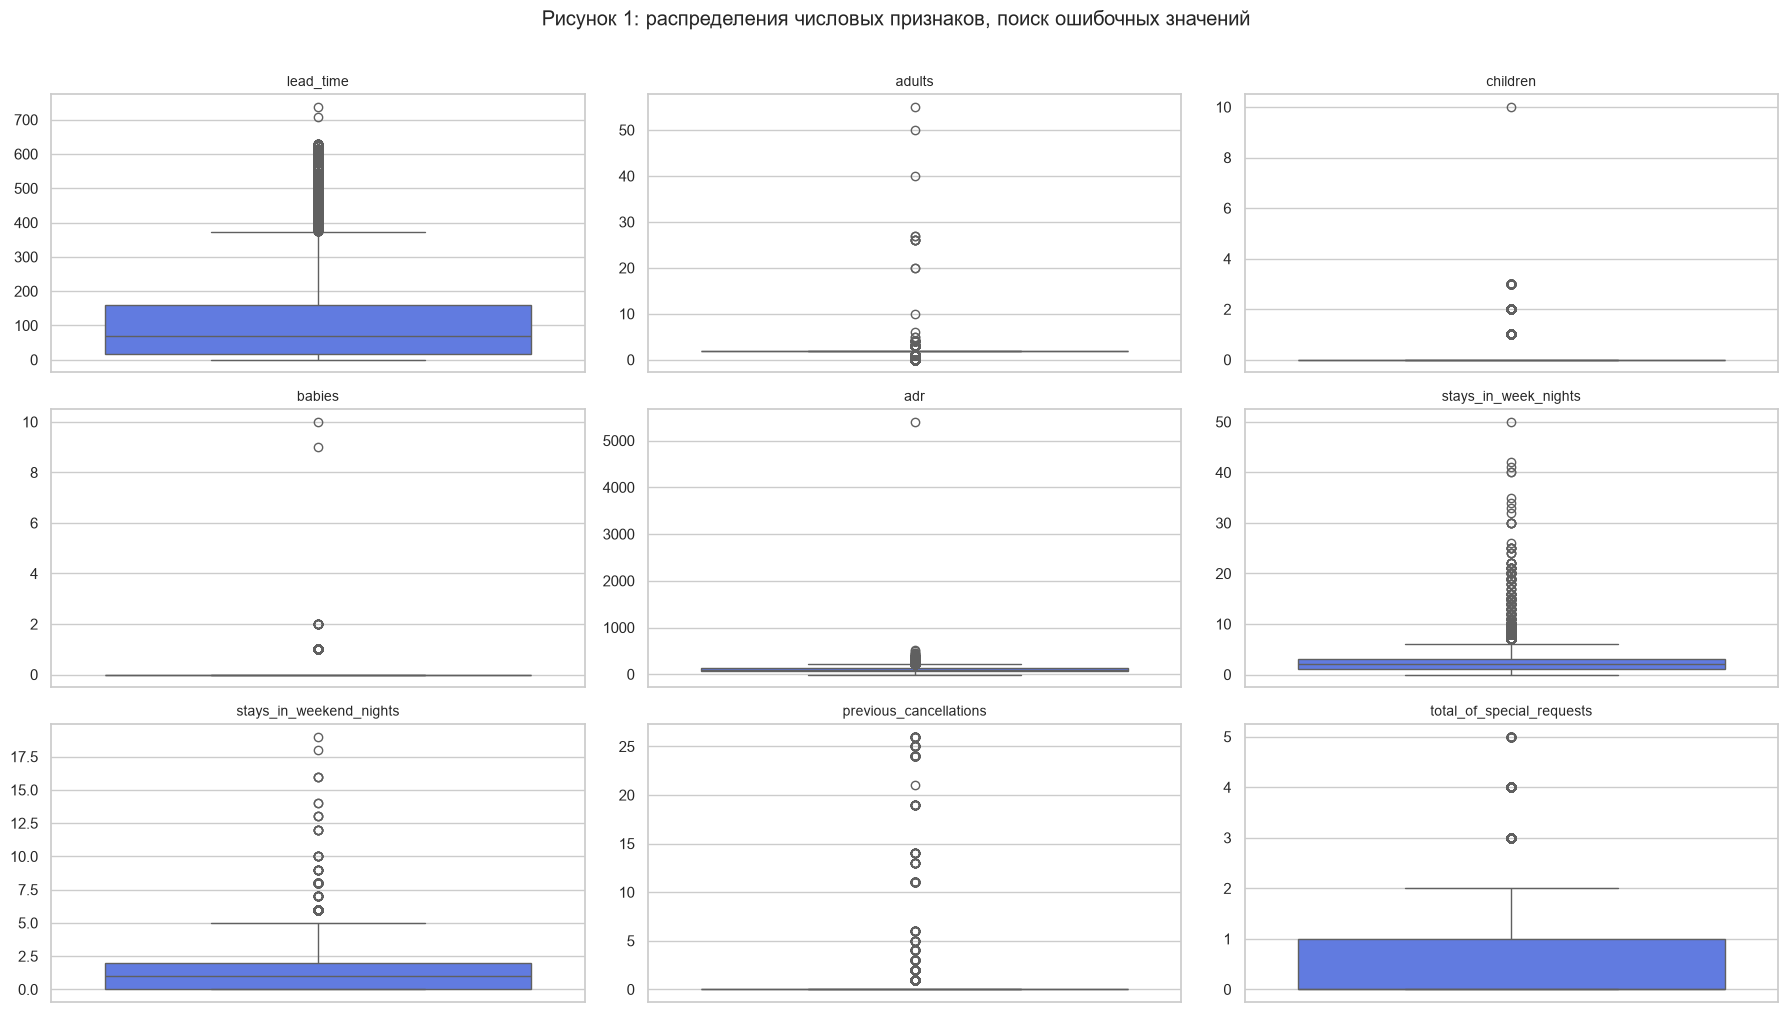

In [18]:
# Распределения числовых признаков
num_cols = [
    "lead_time",
    "adults",
    "children",
    "babies",
    "adr",
    "stays_in_week_nights",
    "stays_in_weekend_nights",
    "previous_cancellations",
    "total_of_special_requests",
]

fig, axes = plt.subplots(3, 3, figsize=(18, 10))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#4C6EF5")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")

plt.suptitle(
    "Рисунок 1: распределения числовых признаков, поиск ошибочных значений",
    y=1.01,
)
plt.tight_layout()
plt.show()

Точки за усами есть почти у всех признаков, но ошибочными из них являются единицы. Boxplot помечает всё, что дальше полутора межквартильных размахов от ящика, а это ещё не признак ошибки.

Максимальный `lead_time` 737 дней - два года, для групповых заявок и квот туроператоров это нормальный горизонт. У `total_of_special_requests` шкала от 0 до 5, выбросов там не бывает по построению: значения 3-5 просто редкие.

Экстремальные значения по составу гостей: 12 броней с числом взрослых больше десяти (максимум 55), одна с десятью детьми, две с девятью и более младенцами. Долгие проживания: 30 броней дольше трёх недель в будни, максимум 50 ночей. История гостя: 39 броней с числом прошлых отмен больше десяти, максимум 26.

Эти значения редкие, но физически возможны: 55 взрослых - групповая заявка, 50 ночей - длительное размещение. Удалять их нет оснований, в модели они растворятся.

Нашлось три типа ошибочных значений: одно отрицательное `adr`, одно значение `adr` 5 400 при медиане 98, и 166 броней с нулевым количеством гостей. Решения по ним приняты в разделе формирования итогового набора признаков.

In [19]:
zero_adults_mask = df['adults'] == 0
zero_adults_count = zero_adults_mask.sum()

print(f"Количество записей с adults == 0: {zero_adults_count} \n")

if zero_adults_count > 0:
    display(
        df.loc[zero_adults_mask, ['hotel', 'adults', 'children', 'babies', 'is_canceled']]
        .head(10)
        .style.set_caption("Таблица 8: Примеры записей с нулевым количеством взрослых")
    )

Количество записей с adults == 0: 403 



,hotel,adults,children,babies,is_canceled
2224,Resort Hotel,0,0,0,0
2409,Resort Hotel,0,0,0,0
3181,Resort Hotel,0,0,0,0
3684,Resort Hotel,0,0,0,0
3708,Resort Hotel,0,0,0,0
4127,Resort Hotel,0,0,0,1
9376,Resort Hotel,0,0,0,1
31765,Resort Hotel,0,0,0,0
32029,Resort Hotel,0,0,0,0
32827,Resort Hotel,0,0,0,0


In [20]:
# Анализ экстремальных значений ADR
adr_negative_count = (df['adr'] < 0).sum()
adr_extreme_count = (df['adr'] > 1000).sum()

print(f"Записей с отрицательным ADR: {adr_negative_count}")
print(f"Записей с ADR > 1000: {adr_extreme_count}")

Записей с отрицательным ADR: 1
Записей с ADR > 1000: 1


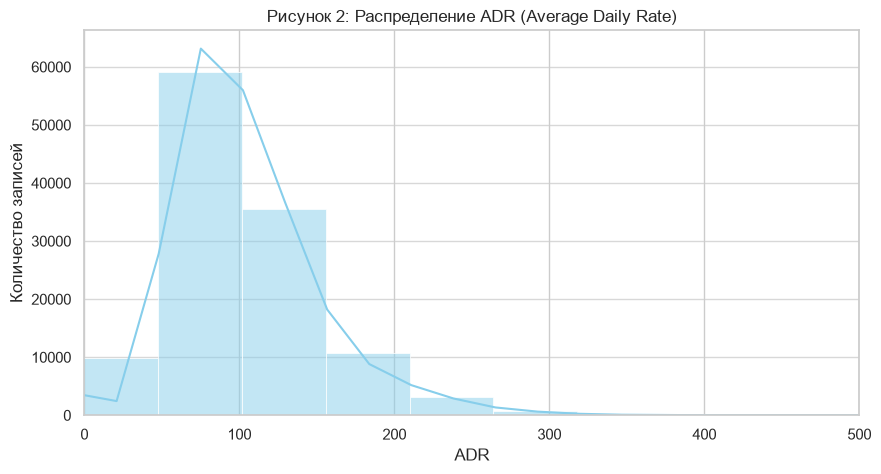

In [21]:
# Визуализация распределения ADR с ограничением оси для наглядности основной массы данных
plt.figure(figsize=(10, 5))
sns.histplot(df['adr'], bins=100, kde=True, color='skyblue')

plt.title('Рисунок 2: Распределение ADR (Average Daily Rate)')
plt.xlabel('ADR')
plt.ylabel('Количество записей')
plt.xlim(0, 500)
plt.grid(axis='y', alpha=0.75)

plt.show()

### Обработка выбросов

Выбросы выявлены по сетке boxplot и проверены по границам правдоподобия. Принятое решение: экстремальные значения сохраняются, обработке подлежат только физически невозможные.

# Связь целевой переменной и признаков

C:\Users\maris\AppData\Local\Temp\ipykernel_26296\2087405073.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hotel', y='is_canceled', data=df, errorbar=None, palette='muted')


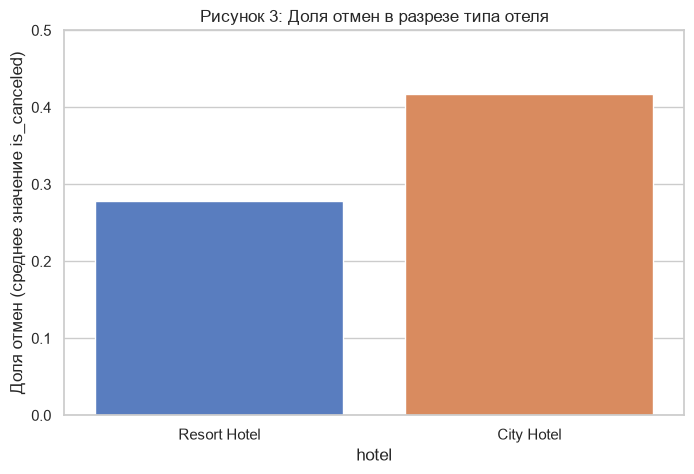

In [22]:
plt.figure(figsize=(8, 5))
sns.barplot(x='hotel', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 3: Доля отмен в разрезе типа отеля')
plt.ylabel('Доля отмен (среднее значение is_canceled)')
plt.ylim(0, 0.5)
plt.show()

C:\Users\maris\AppData\Local\Temp\ipykernel_26296\2433202519.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='deposit_type', y='is_canceled', data=df, errorbar=None, palette='muted')


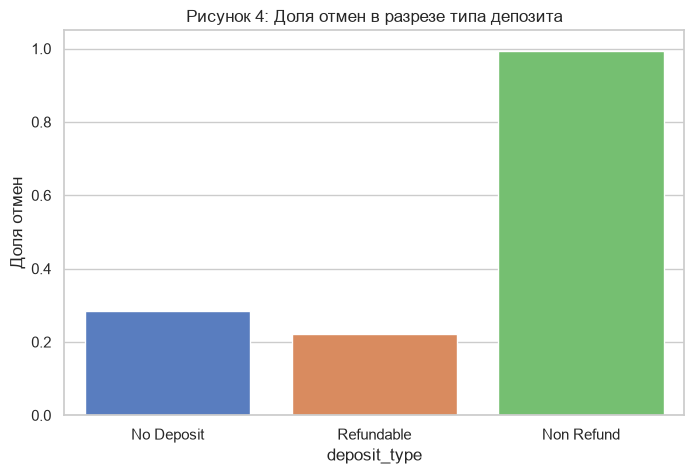

In [23]:
plt.figure(figsize=(8, 5))
sns.barplot(x='deposit_type', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 4: Доля отмен в разрезе типа депозита')
plt.ylabel('Доля отмен')
plt.ylim(0, 1.05)
plt.show()

In [24]:
# Поведение каждого категориального признака в отдельности
cat_cols = ['hotel', 'meal', 'market_segment', 'distribution_channel',
            'customer_type', 'reserved_room_type', 'is_repeated_guest']

for col in cat_cols:
    table = (df.groupby(col)['is_canceled']
             .agg(Броней='size', Доля_отмен='mean').round(3)
             .sort_values('Доля_отмен', ascending=False))
    table = table[table['Броней'] >= 100]
    print(f"\n--- {col} ---")
    print(table.to_string())

print(f"\nВ среднем по данным: {df['is_canceled'].mean():.3f}")


--- hotel ---
              Броней  Доля_отмен
hotel                           
City Hotel     79330       0.417
Resort Hotel   40060       0.278

--- meal ---
           Броней  Доля_отмен
meal                         
FB            798       0.599
BB          92310       0.374
SC          10650       0.372
HB          14463       0.345
Undefined    1169       0.245

--- market_segment ---
                Броней  Доля_отмен
market_segment                    
Groups           19811       0.611
Online TA        56477       0.367
Offline TA/TO    24219       0.343
Aviation           237       0.219
Corporate         5295       0.187
Direct           12606       0.153
Complementary      743       0.131

--- distribution_channel ---
                      Броней  Доля_отмен
distribution_channel                    
TA/TO                  97870       0.410
Corporate               6677       0.221
GDS                      193       0.192
Direct                 14645       0.175

--- customer_

In [25]:
# Бинарные разрезы по счётчикам истории гостя
for col in ['previous_cancellations', 'previous_bookings_not_canceled',
            'total_of_special_requests', 'booking_changes']:
    has = df[col] > 0
    print(f"{col:32s} >0: {has.sum():6,} броней, отмен {df.loc[has, 'is_canceled'].mean():.3f} | "
          f"=0: {(~has).sum():6,}, отмен {df.loc[~has, 'is_canceled'].mean():.3f}")

previous_cancellations           >0:  6,484 броней, отмен 0.916 | =0: 112,906, отмен 0.339
previous_bookings_not_canceled   >0:  3,620 броней, отмен 0.055 | =0: 115,770, отмен 0.380
total_of_special_requests        >0: 49,072 броней, отмен 0.217 | =0: 70,318, отмен 0.477
booking_changes                  >0: 18,076 броней, отмен 0.157 | =0: 101,314, отмен 0.409


### Выводы по отдельным признакам

Сильнее всего отмену предсказывает история гостя. Если он раньше доезжал, то отменяет в 5.0% случаев против 28.4% у остальных; если раньше отменял – в 67.9%. Это единственные три признака, которые описывают человека, а не параметры брони. Мешает одно: хоть какая-то история есть только у 5.8% записей.

Канал продаж, в отличие от истории, работает на всём массиве и даёт устойчивый трёхкратный разрыв – 35.3% у онлайн-турагентств против 12.1% у корпоративных броней. При этом `market_segment` и `distribution_channel` описывают одно и то же разными словами: 51 316 из 51 618 броней `Online TA` идут каналом `TA/TO`.

Отдельно по питанию. Категории `SC` и `Undefined` выглядят синонимами, "без питания" и "не указано". Доли отмен – 35.3% и 16.7%.

Самое неприятное обнаружилось на пересечении признаков. Бронь через онлайн-турагентство, у гостя нет истории, специальных пожеланий нет: 18 361 запись, 21% данных, доля отмен 53%. Все сильные сигналы молчат одновременно.

Остальное ожидаемо – городской отель 30.0% против курортного 23.5%, тип клиента `Transient` 30.1% против `Group` 9.9%, типы номеров различаются слабо.

C:\Users\maris\AppData\Local\Temp\ipykernel_26296\2211733654.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lead_time_bin', y='is_canceled', data=df, errorbar=None, palette='muted')


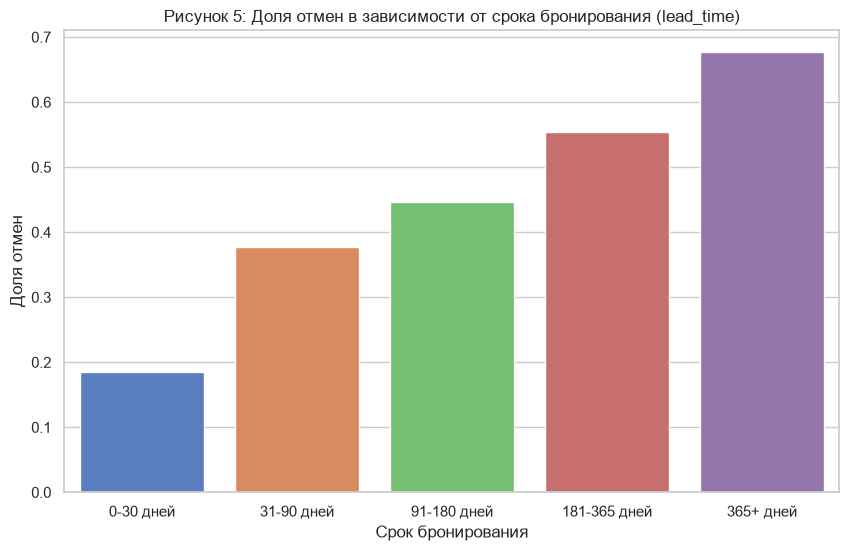

In [26]:
df['lead_time_bin'] = pd.cut(df['lead_time'],
                             bins=[-1, 30, 90, 180, 365, 10000],
                             labels=['0-30 дней', '31-90 дней', '91-180 дней', '181-365 дней', '365+ дней'])

plt.figure(figsize=(10, 6))
sns.barplot(x='lead_time_bin', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 5: Доля отмен в зависимости от срока бронирования (lead_time)')
plt.ylabel('Доля отмен')
plt.xlabel('Срок бронирования')
plt.show()

In [27]:
print(df['lead_time_bin'].isna().sum())   # должно быть 0

0


,Броней,Доля_отмен
adr,,
0 (бесплатно),1959,0.109
1-50,10037,0.232
51-80,31391,0.404
81-110,34161,0.383
111-150,25333,0.380
151-200,11579,0.380
200+,4929,0.384


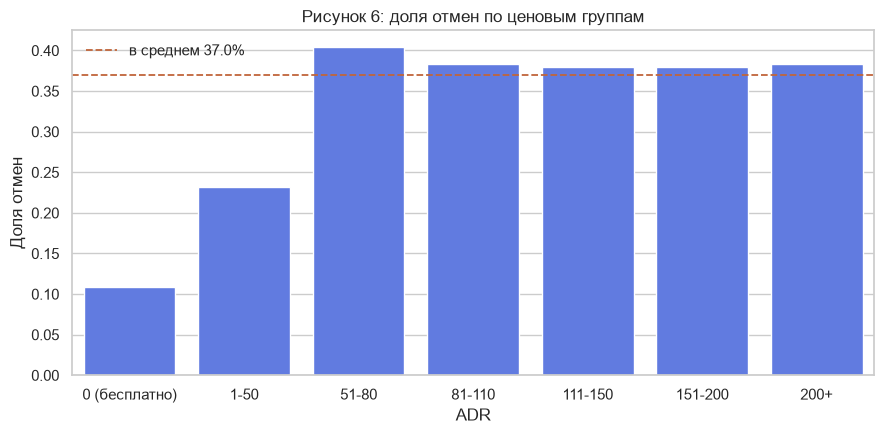

In [28]:
# Связь цены с отменами
price_bins = pd.cut(df['adr'], [-1, 0, 50, 80, 110, 150, 200, 10000],
                    labels=['0 (бесплатно)', '1-50', '51-80', '81-110',
                            '111-150', '151-200', '200+'])

price_table = (df.groupby(price_bins, observed=True)['is_canceled']
               .agg(Броней='size', Доля_отмен='mean').round(3))
display(price_table.style.set_caption("Таблица N: доля отмен по ценовым группам"))

plt.figure(figsize=(9, 4.5))
sns.barplot(x=price_bins, y=df['is_canceled'], errorbar=None, color='#4C6EF5')
plt.axhline(df['is_canceled'].mean(), color='#C0653A', ls='--', lw=1.3,
            label=f"в среднем {df['is_canceled'].mean():.1%}")
plt.title('Рисунок 6: доля отмен по ценовым группам')
plt.xlabel('ADR')
plt.ylabel('Доля отмен')
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Чем дороже бронь, тем чаще её отменяют: от 10.4% у бесплатных размещений до 37.6% у броней дороже 200. Рост монотонный на всём диапазоне.

Корреляция `adr` с отменой составляет 0.128 и эту связь недооценивает: зависимость нелинейна, основной подъём приходится на участок от 50 до 150, где лежит 71% данных.

Проверка на смешение с типом отеля: внутри City Hotel рост идёт с 20.8% до 35.8%, внутри Resort Hotel - с 15.6% до 38.5%. Эффект цены сохраняется в обоих отелях, то есть не объясняется тем, что городской отель дороже и отменяется чаще.

Отдельная группа - бесплатные размещения с нулевым `adr`. Их 1 778, доля отмен 10.4%, то есть вдвое с лишним ниже среднего. Нулевая цена здесь не пропуск, а служебное или комплиментарное размещение, и признак несёт сигнал.

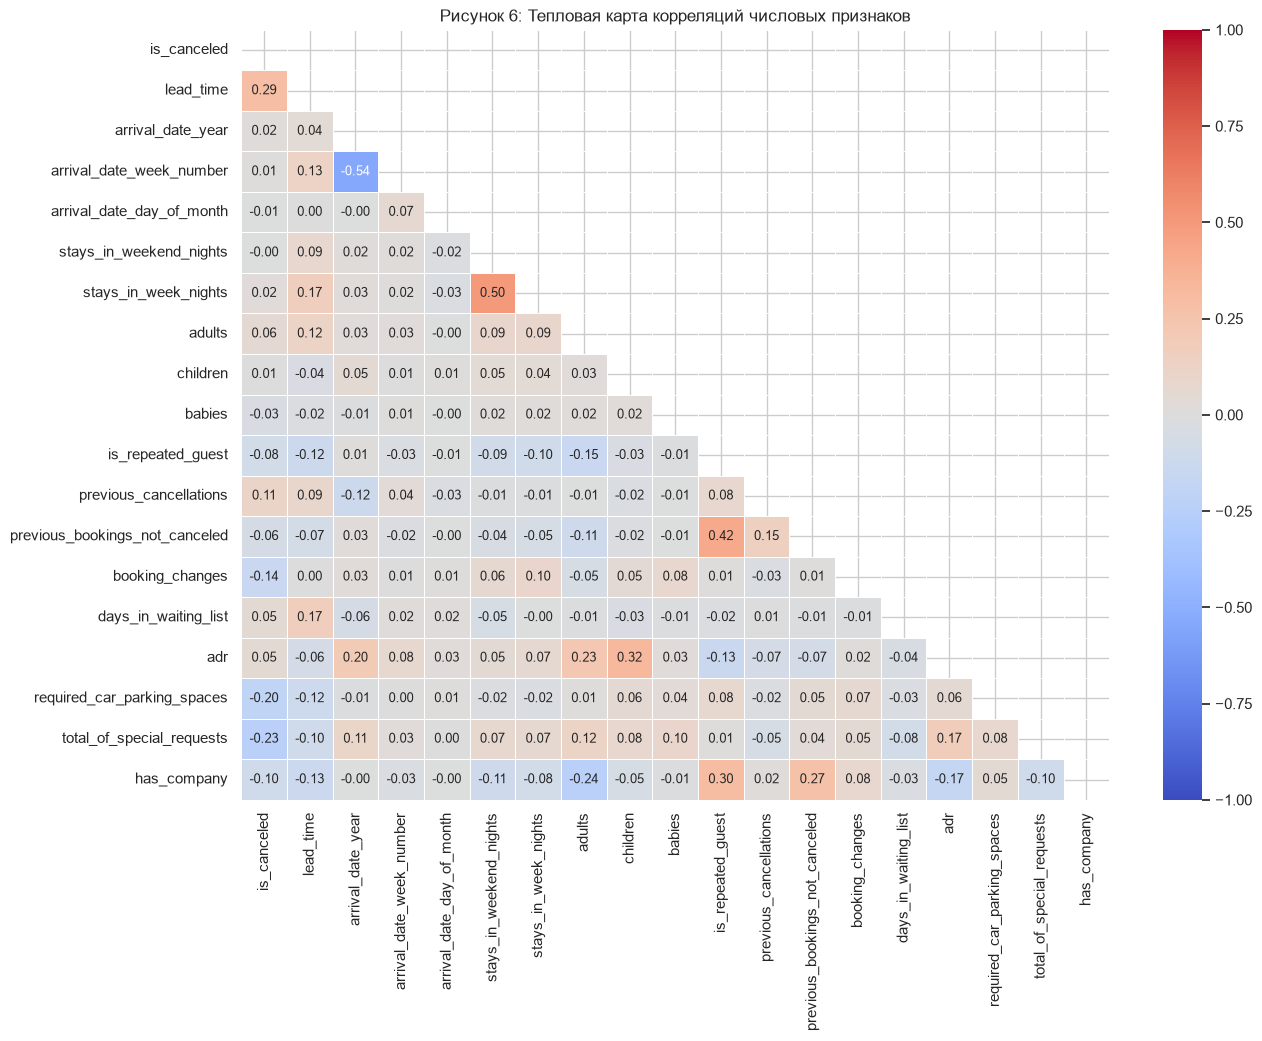

In [29]:
# Тепловая карта корреляций только для числовых признаков
numeric_cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(14, 10))
correlation_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title('Рисунок 6: Тепловая карта корреляций числовых признаков')
plt.show()

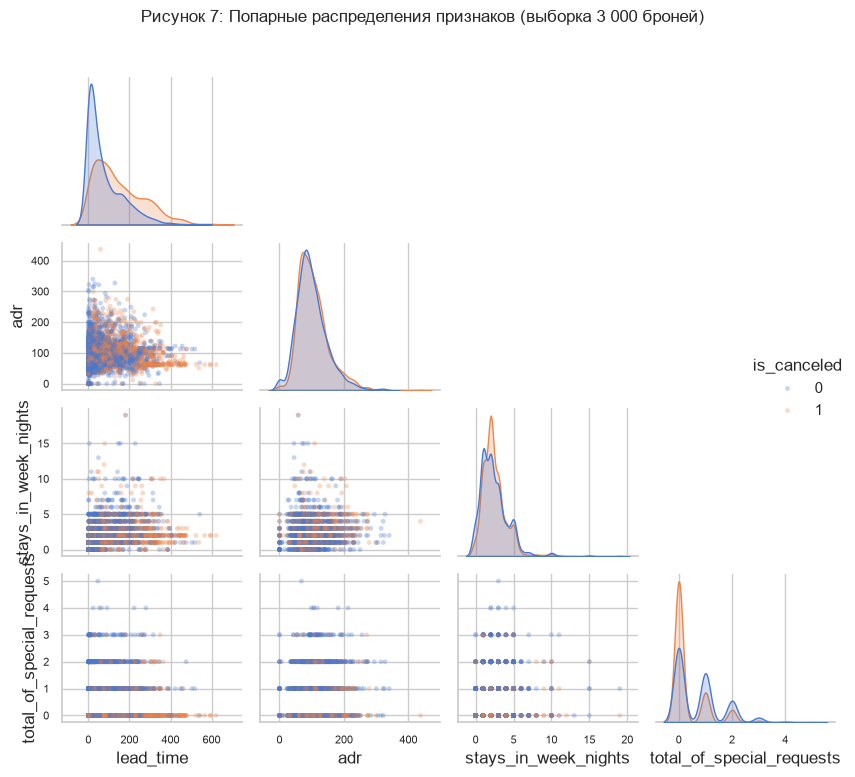

In [30]:
# Попарные распределения признаков
pair_cols = ["lead_time", "adr", "stays_in_week_nights", "total_of_special_requests"]

g = sns.pairplot(df[pair_cols + ["is_canceled"]].sample(3000, random_state=42),
                 hue="is_canceled", corner=True, height=1.9,
                 plot_kws={"alpha": 0.3, "s": 12, "edgecolor": "none"},
                 diag_kws={"common_norm": False})
g.figure.suptitle("Рисунок 7: Попарные распределения признаков (выборка 3 000 броней)",
                  y=1.02, fontsize=12)
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

### Выводы по попарным распределениям

Ни одна пара признаков не делит брони на отменённые и состоявшиеся: синие и оранжевые точки лежат вперемешку на всех графиках. Разница заметна только на диагонали, где показано распределение каждого признака по отдельности. Сильнее всего она видна у `lead_time`: оранжевая кривая сдвинута вправо, то есть отменённые брони делают заранее, а не перед самым заездом.

Простая формула вида "если срок больше N дней и цена выше M - значит отменят" работать не будет, таких границ в данных нет. Значит, нужны модели, которые умеют учитывать сочетания признаков, а не каждый по отдельности.

# Анализ параметров с возможной утечкой данных

In [31]:
print("Таблица 9: Количество записей по типу депозита")
display(df['deposit_type'].value_counts().to_frame())

Таблица 9: Количество записей по типу депозита


,count
deposit_type,
No Deposit,104641
Non Refund,14587
Refundable,162


In [32]:
print("Таблица 10: Доля отмен для Non Refund по отелям")
non_refund_data = df[df['deposit_type'] == 'Non Refund']
display(non_refund_data.groupby('hotel')['is_canceled'].mean().to_frame())

Таблица 10: Доля отмен для Non Refund по отелям


,is_canceled
hotel,
City Hotel,0.998135
Resort Hotel,0.959860


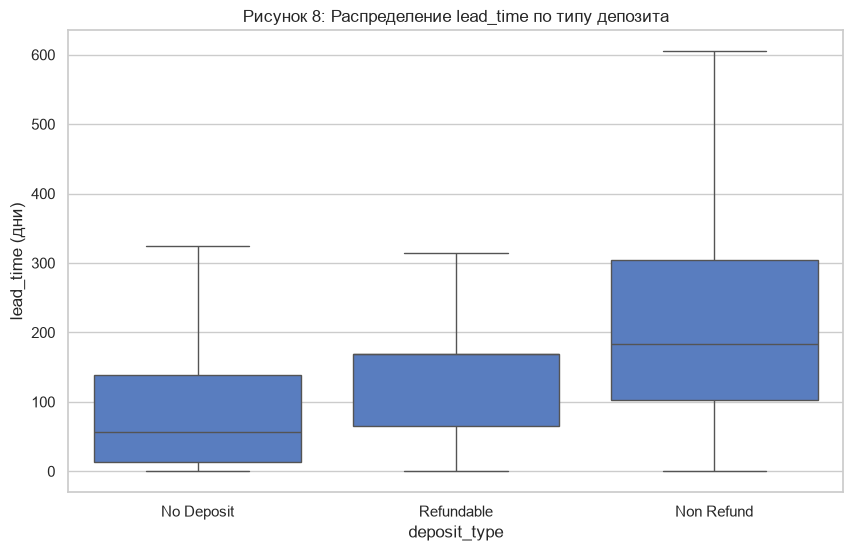

In [33]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='deposit_type', y='lead_time', data=df, showfliers=False)
plt.title('Рисунок 8: Распределение lead_time по типу депозита')
plt.ylabel('lead_time (дни)')
plt.show()

In [34]:
print("Таблица 11: Среднее количество изменений брони по типу депозита")
display(df.groupby('deposit_type')['booking_changes'].mean().to_frame())

Таблица 11: Среднее количество изменений брони по типу депозита


,booking_changes
deposit_type,
No Deposit,0.249634
Non Refund,0.012477
Refundable,0.592593


In [35]:
print("Таблица 12: Доля отмен по deposit_type")
display(df.groupby('deposit_type')['is_canceled'].mean().to_frame())

Таблица 12: Доля отмен по deposit_type


,is_canceled
deposit_type,
No Deposit,0.283770
Non Refund,0.993624
Refundable,0.222222


In [36]:
# Пробуем сгладить влияние параметра с утечкой
df['has_deposit'] = (df['deposit_type'] != 'No Deposit').astype(int)

print("Таблица 13: Доля отмен по has_deposit")
display(df.groupby('has_deposit')['is_canceled'].mean().to_frame())

Таблица 13: Доля отмен по has_deposit


,is_canceled
has_deposit,
0,0.283770
1,0.985152


In [37]:
leakage_candidates = [
    'assigned_room_type',      # может измениться при заезде
    'reservation_status_date', # точно после бронирования
    'booking_changes',         # меняется со временем
    'days_in_waiting_list'     # меняется со временем
]

print("Анализ потенциальных утечек данных")

for col in leakage_candidates:
    print(f"--- {col} ---")
    print(f"Уникальных значений: {df[col].nunique()}")
    print(f"Первые 10 значений:")
    print(df[col].value_counts().head(3))
    print()

Анализ потенциальных утечек данных
--- assigned_room_type ---
Уникальных значений: 12
Первые 10 значений:
assigned_room_type
A    74053
D    25322
E     7806
Name: count, dtype: int64

--- reservation_status_date ---
Уникальных значений: 926
Первые 10 значений:
reservation_status_date
2015-10-21    1461
2015-07-06     805
2016-11-25     790
Name: count, dtype: int64

--- booking_changes ---
Уникальных значений: 21
Первые 10 значений:
booking_changes
0    101314
1     12701
2      3805
Name: count, dtype: int64

--- days_in_waiting_list ---
Уникальных значений: 128
Первые 10 значений:
days_in_waiting_list
0     115692
39       227
58       164
Name: count, dtype: int64



In [38]:
room_comparison = pd.crosstab(
    df['reserved_room_type'],
    df['assigned_room_type'],
    margins=True
)

display(room_comparison.style.set_caption("Таблица 14: Соответствие зарезервированного и назначенного типа номера"))

room_changed = (df['reserved_room_type'] != df['assigned_room_type']).mean()
print()
print(f"Доля бронирований, где тип номера изменился: {room_changed:.4%}")

assigned_room_type,A,B,C,D,E,F,G,H,I,K,L,P,All
reserved_room_type,,,,,,,,,,,,,
A,73598,1123,1447,7548,1156,417,186,94,215,210,0,0,85994
B,111,988,0,5,2,2,8,0,0,2,0,0,1118
C,5,2,883,6,4,2,10,10,10,0,0,0,932
D,312,27,34,17736,686,204,82,9,67,44,0,0,19201
E,15,3,8,22,5923,404,100,4,40,16,0,0,6535
F,6,17,0,4,31,2707,116,3,10,3,0,0,2897
G,5,2,2,0,4,14,2041,7,15,4,0,0,2094
H,0,0,0,1,0,0,10,584,6,0,0,0,601
L,1,1,1,0,0,1,0,1,0,0,1,0,6



Доля бронирований, где тип номера изменился: 12.4943%


In [39]:
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}

df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'].map(month_map).astype(str) + '-' +
    df['arrival_date_day_of_month'].astype(str)
)

df['booking_date'] = df['arrival_date'] - pd.to_timedelta(df['lead_time'], unit='D')

print(f"Диапазон: {df['booking_date'].min().date()} до {df['booking_date'].max().date()}")

Диапазон: 2013-06-24 до 2017-08-31


In [40]:
print("Анализ reservation_status_date \n")

df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
print(f"Диапазон дат изменения статуса: {df['reservation_status_date'].min()} до {df['reservation_status_date'].max()}")
print(f"Диапазон дат бронирования (booking_date): {df['booking_date'].min()} до {df['booking_date'].max()}")

# Проверяем, есть ли случаи, когда статус изменился ДО бронирования
status_before_booking = (df['reservation_status_date'] < df['booking_date']).sum()
print(f"Количество записей, где статус изменился ДО бронирования: {status_before_booking}")

# Проверяем, есть ли случаи, когда статус изменился ПОСЛЕ заезда
status_after_arrival = (df['reservation_status_date'] > df['arrival_date']).sum()
print(f"Количество записей, где статус изменился ПОСЛЕ заезда: {status_after_arrival}")

Анализ reservation_status_date 

Диапазон дат изменения статуса: 2014-10-17 00:00:00 до 2017-09-14 00:00:00
Диапазон дат бронирования (booking_date): 2013-06-24 00:00:00 до 2017-08-31 00:00:00
Количество записей, где статус изменился ДО бронирования: 0
Количество записей, где статус изменился ПОСЛЕ заезда: 74460


In [41]:
# Сравнительная статистика lead_time для отмененных и успешных бронирований
lead_time_stats = df.groupby('is_canceled')['lead_time'].agg(['count', 'mean', 'median', 'max']).round(1)

# Переименуем индексы для наглядности
lead_time_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']

display(lead_time_stats.style.set_caption("Таблица 15: Сравнение сроков бронирования по факту заезда"))

,count,mean,median,max
0: Успешный заезд,75166,80.000,45.000,737
1: Отмена / No-Show,44224,144.800,113.000,629


C:\Users\maris\AppData\Local\Temp\ipykernel_26296\3406199913.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
findfont: Failed to find font weight semibold for Arial, now using 700.


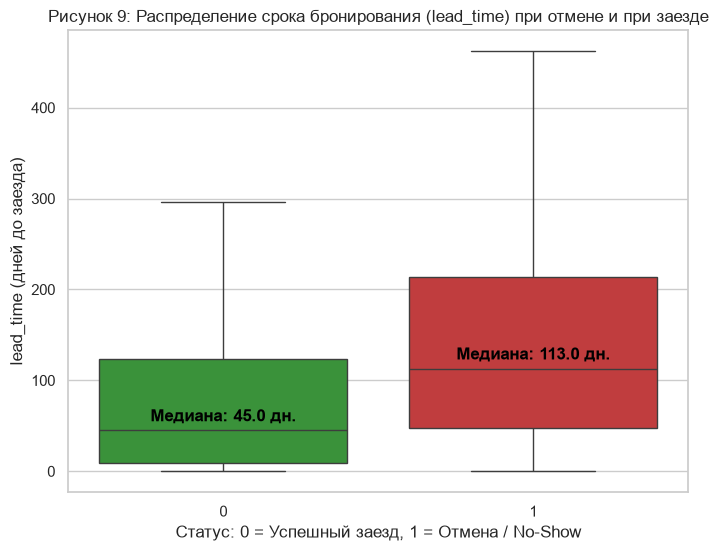

In [42]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x='is_canceled',
    y='lead_time',
    data=df,
    showfliers=False,
    palette=['#2ca02c', '#d62728']
)

plt.title('Рисунок 9: Распределение срока бронирования (lead_time) при отмене и при заезде')
plt.xlabel('Статус: 0 = Успешный заезд, 1 = Отмена / No-Show')
plt.ylabel('lead_time (дней до заезда)')

medians = df.groupby('is_canceled')['lead_time'].median().values
for i, median in enumerate(medians):
    plt.text(i, median + 10, f'Медиана: {median} дн.',
             horizontalalignment='center', size='medium', color='black', weight='semibold')

plt.show()

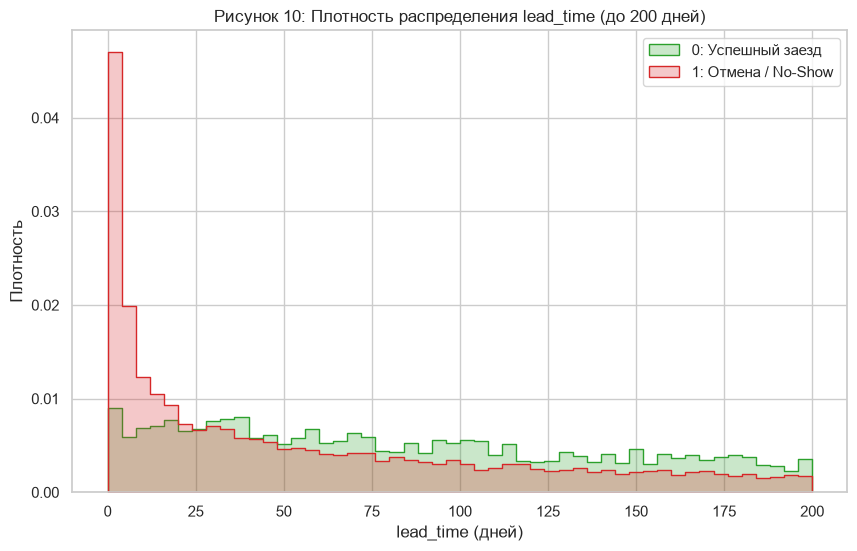

In [43]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df[df['lead_time'] <= 200], # Фильтруем экстремальные хвосты
    x='lead_time',
    hue='is_canceled',
    element='step',
    stat='density',
    common_norm=False,
    palette=['#d62728', '#2ca02c']
)

plt.title('Рисунок 10: Плотность распределения lead_time (до 200 дней)')
plt.xlabel('lead_time (дней)')
plt.ylabel('Плотность')
plt.legend(['0: Успешный заезд', '1: Отмена / No-Show'])
plt.show()

In [44]:
print("Пропусков в данных:", df.isna().sum().sum())
print("Строк:", len(df), "| столбцов:", df.shape[1])

Пропусков в данных: 0
Строк: 119390 | столбцов: 36


In [45]:
# Анализ признака required_car_parking_spaces
display(df['required_car_parking_spaces'].value_counts().to_frame()
        .style.set_caption("Таблица 16: Количество запросов парковочных мест"))

print("\n")

cross_parking = pd.crosstab(df['required_car_parking_spaces'], df['is_canceled'], margins=True)
display(cross_parking.style.set_caption("Таблица 17: Связь парковки с отменами"))

print("\n")

parking_cancel_rate = df.groupby('required_car_parking_spaces')['is_canceled'].agg(['count', 'mean']).round(4)
display(parking_cancel_rate.style.set_caption("Таблица 18: Доля отмен по количеству запрошенных мест"))

print("\n")

# есть ли отмены среди тех, кто запросил парковку?
parking_requests = df[df['required_car_parking_spaces'] > 0]
print(f"Всего броней с запросом парковки: {len(parking_requests)}")
print(f"Из них отменено: {parking_requests['is_canceled'].sum()}")
print(f"Доля отмен: {parking_requests['is_canceled'].mean():.4f}")

,count
required_car_parking_spaces,
0,111974
1,7383
2,28
3,3
8,2


is_canceled,0,1,All
required_car_parking_spaces,,,
0,67750,44224,111974
1,7383,0,7383
2,28,0,28
3,3,0,3
8,2,0,2
All,75166,44224,119390


,count,mean
required_car_parking_spaces,,
0,111974,0.395
1,7383,0.000
2,28,0.000
3,3,0.000
8,2,0.000




Всего броней с запросом парковки: 7416
Из них отменено: 0
Доля отмен: 0.0000


required_car_parking_spaces — target leakage. Признак подлежит удалению.

In [46]:
changes_stats = df.groupby('is_canceled')['booking_changes'].agg(['count', 'mean', 'median', 'max']).round(3)
changes_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']
display(changes_stats.style.set_caption("Таблица 19: Статистика booking_changes по группам"))

print("\n")

changes_crosstab = pd.crosstab(df['booking_changes'], df['is_canceled'], margins=True)
display(changes_crosstab.style.set_caption("Таблица 20: booking_changes против is_canceled"))

canceled_with_changes = df[(df['is_canceled'] == 1) & (df['booking_changes'] > 0)].shape[0]
print(f"Отменённых броней с ненулевым числом изменений: {canceled_with_changes}")

,count,mean,median,max
0: Успешный заезд,75166,0.293,0.000,21
1: Отмена / No-Show,44224,0.098,0.000,16


is_canceled,0,1,All
booking_changes,,,
0,59923,41391,101314
1,10894,1807,12701
2,3039,766,3805
3,783,144,927
4,309,67,376
5,98,20,118
6,45,18,63
7,28,3,31
8,13,4,17


Отменённых броней с ненулевым числом изменений: 2833


In [47]:
waiting_stats = df.groupby('is_canceled')['days_in_waiting_list'].agg(['count', 'mean', 'median', 'max']).round(3)
waiting_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']
display(waiting_stats.style.set_caption("Таблица 21: Статистика days_in_waiting_list по группам"))

print("\n")

was_in_waiting_list = (df['days_in_waiting_list'] > 0).astype(int)
waiting_crosstab = pd.crosstab(was_in_waiting_list, df['is_canceled'], margins=True)
display(waiting_crosstab.style.set_caption("Таблица 22: was_in_waiting_list против is_canceled"))

canceled_with_waiting = df[(df['is_canceled'] == 1) & (df['days_in_waiting_list'] > 0)].shape[0]
print(f"Отменённых броней, побывавших в листе ожидания: {canceled_with_waiting}")

,count,mean,median,max
0: Успешный заезд,75166,1.590,0.000,379
1: Отмена / No-Show,44224,3.564,0.000,391


is_canceled,0,1,All
days_in_waiting_list,,,
0,73827,41865,115692
1,1339,2359,3698
All,75166,44224,119390


Отменённых броней, побывавших в листе ожидания: 2359


In [48]:
requests_stats = df.groupby('is_canceled')['total_of_special_requests'].agg(['count', 'mean', 'median', 'max']).round(3)
requests_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']
display(requests_stats.style.set_caption("Таблица 23: Статистика total_of_special_requests по группам"))

print("\n")

requests_crosstab = pd.crosstab(df['total_of_special_requests'], df['is_canceled'], margins=True)
display(requests_crosstab.style.set_caption("Таблица 24: total_of_special_requests против is_canceled"))

canceled_with_requests = df[(df['is_canceled'] == 1) & (df['total_of_special_requests'] > 0)].shape[0]
print(f"Отменённых броней со специальными запросами: {canceled_with_requests}")

,count,mean,median,max
0: Успешный заезд,75166,0.714,1.000,5
1: Отмена / No-Show,44224,0.329,0.000,5


is_canceled,0,1,All
total_of_special_requests,,,
0,36762,33556,70318
1,25908,7318,33226
2,10103,2866,12969
3,2051,446,2497
4,304,36,340
5,38,2,40
All,75166,44224,119390


Отменённых броней со специальными запросами: 10668


# Анализ временных признаков

Со временем бронирования связаны шесть столбцов: `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month`, `stays_in_week_nights` и `stays_in_weekend_nights`. Все они известны в момент создания брони, поэтому утечкой не являются. Вопрос в том, какие из них нужны модели и в каком виде.

## Покрытие периода

In [49]:
t_month_map = {m: i + 1 for i, m in enumerate(
    ['January', 'February', 'March', 'April', 'May', 'June',
     'July', 'August', 'September', 'October', 'November', 'December'])}

t_df = df[['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month',
           'arrival_date_day_of_month', 'stays_in_week_nights', 'stays_in_weekend_nights']].copy()
t_df['arrival_month'] = t_df['arrival_date_month'].map(t_month_map)
t_df['arrival_date'] = pd.to_datetime(dict(year=t_df['arrival_date_year'],
                                           month=t_df['arrival_month'],
                                           day=t_df['arrival_date_day_of_month']))

print("Таблица 25: Покрытие периода и доля отмен по годам заезда")
t_cover = t_df.groupby('arrival_date_year').agg(
    броней=('is_canceled', 'size'),
    доля_отмен=('is_canceled', 'mean'),
    первый_заезд=('arrival_date', 'min'),
    последний_заезд=('arrival_date', 'max'))
t_cover['доля_отмен'] = t_cover['доля_отмен'].round(3)
display(t_cover)

print("Таблица 26: Число броней по месяцу и году заезда")
display(pd.crosstab(t_df['arrival_month'], t_df['arrival_date_year']))

Таблица 25: Покрытие периода и доля отмен по годам заезда


,броней,доля_отмен,первый_заезд,последний_заезд
arrival_date_year,,,,
2015,21996,0.370,2015-07-01,2015-12-31
2016,56707,0.359,2016-01-01,2016-12-31
2017,40687,0.387,2017-01-01,2017-08-31


Таблица 26: Число броней по месяцу и году заезда


arrival_date_year,2015,2016,2017
arrival_month,,,
1,0,2248,3681
2,0,3891,4177
3,0,4824,4970
4,0,5428,5661
5,0,5478,6313
6,0,5292,5647
7,2776,4572,5313
8,3889,5063,4925
9,5114,5394,0


In [50]:
t_dom = t_df.groupby('arrival_date_day_of_month')['is_canceled'].mean()
t_mon = t_df.groupby('arrival_month')['is_canceled'].mean()
print(f"Доля отмен по дню месяца: min={t_dom.min():.3f}, max={t_dom.max():.3f}, std={t_dom.std():.3f}")
print(f"Доля отмен по месяцу заезда: min={t_mon.min():.3f}, max={t_mon.max():.3f}, std={t_mon.std():.3f}")

Доля отмен по дню месяца: min=0.325, max=0.420, std=0.026
Доля отмен по месяцу заезда: min=0.305, max=0.415, std=0.038


### Выводы по году, неделе и дню месяца

**Год.** В данных три значения. Заезды идут подряд с июля 2015 по август 2017 (26 месяцев), каждый месяц встречается минимум в двух годах, июль и август - во всех трёх. Календарно полный год только 2016. Доля отмен растёт от года к году: 20.3% в 2015, 26.4% в 2016, 31.9% в 2017, причём у обоих отелей. Для января-августа это видно напрямую: в 2017 году отмен больше, чем в 2016, на 6 пунктов и у City (34.0% против 27.7%), и у Resort (28.3% против 21.9%). Это сдвиг уровня, а не сезонность. Перенести его на новые периоды нельзя: год описывает только то, что уже было, и не экстраполируется.

**Номер недели.** Нумерация в данных не совпадает со стандартной: неделя начинается с воскресенья, а "неделя 53" неполная и приходится на конец декабря. Информации сверх месяца и дня недели такой признак не несёт.

**День месяца.** Доля отмен по дням месяца колеблется в узком диапазоне, 25.4-29.6% (std 0.013), тогда как по месяцам заезда диапазон 21.1-32.2% (std 0.040). Сигнала в дне месяца почти нет.

## Сезонность

Сравниваем долю отмен по месяцу заезда отдельно для двух отелей и по годам (рисунок 11, чёрная линия - все годы вместе).

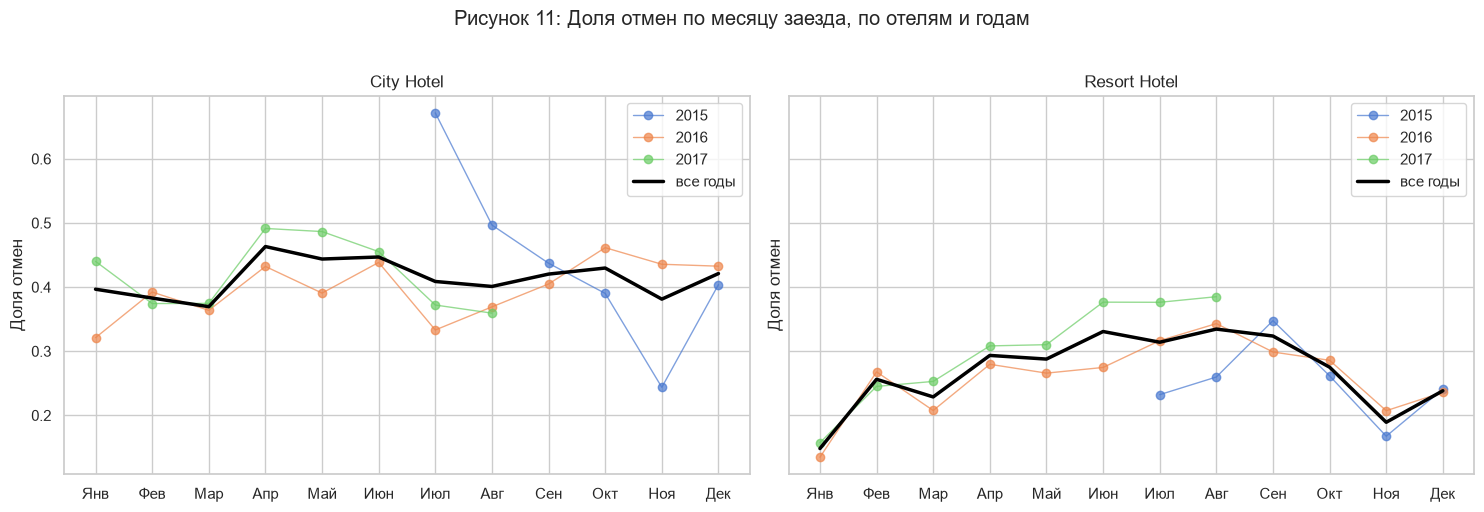

In [51]:
t_month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, hotel in zip(axes, ['City Hotel', 'Resort Hotel']):
    t_h = t_df[t_df['hotel'] == hotel]
    t_hy = t_h.groupby(['arrival_month', 'arrival_date_year'])['is_canceled'].mean().unstack()
    for year in t_hy.columns:
        ax.plot(t_hy.index, t_hy[year], marker='o', linewidth=1, alpha=0.7, label=str(year))
    t_all = t_h.groupby('arrival_month')['is_canceled'].mean()
    ax.plot(t_all.index, t_all.values, color='black', linewidth=2.5, label='все годы')
    ax.set_title(hotel)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(t_month_names)
    ax.set_ylabel('Доля отмен')
    ax.legend()
fig.suptitle('Рисунок 11: Доля отмен по месяцу заезда, по отелям и годам', y=1.02)
plt.tight_layout()
plt.show()

In [52]:
t_hy = t_df.groupby(['hotel', 'arrival_date_year', 'arrival_month'])['is_canceled'].mean().unstack('arrival_date_year')
t_common = t_hy.dropna(subset=[2016, 2017])
print("Корреляция месячного профиля отмен 2016 и 2017 (январь-август, 8 точек на отель):")
print(t_common.groupby('hotel').apply(lambda g: g[2016].corr(g[2017])).round(2).to_string())

print("\nТаблица 27: Средний lead_time по месяцу заезда (дни)")
t_lead = t_df.groupby(['hotel', 'arrival_month'])['lead_time'].mean().unstack().round(0)
t_lead.columns = t_month_names
display(t_lead)

Корреляция месячного профиля отмен 2016 и 2017 (январь-август, 8 точек на отель):
hotel
City Hotel      0.52
Resort Hotel    0.90

Таблица 27: Средний lead_time по месяцу заезда (дни)


,Янв,Фев,Мар,Апр,Май,Июн,Июл,Авг,Сен,Окт,Ноя,Дек
hotel,,,,,,,,,,,,
City Hotel,57.0,53.0,73.0,99.0,116.0,124.0,154.0,131.0,128.0,126.0,94.0,85.0
Resort Hotel,26.0,40.0,64.0,86.0,121.0,138.0,106.0,103.0,158.0,117.0,45.0,56.0


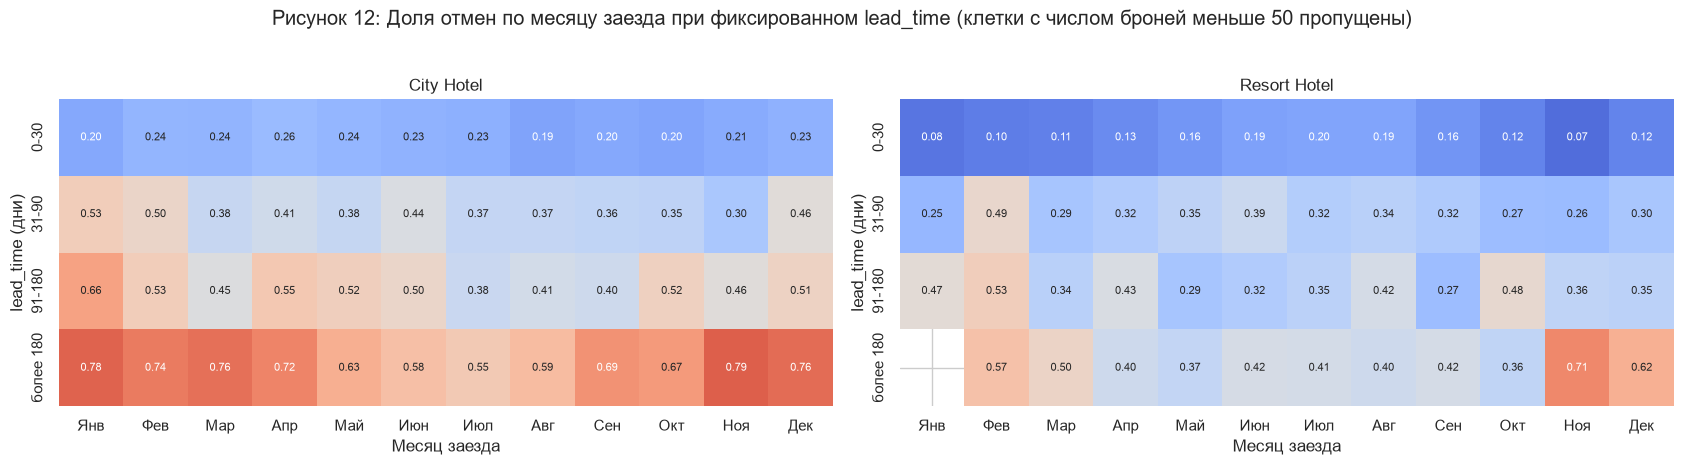

In [53]:
t_df['lead_bin'] = pd.cut(t_df['lead_time'], [-1, 30, 90, 180, 10000],
                          labels=['0-30', '31-90', '91-180', 'более 180'])
t_grp = t_df.groupby(['hotel', 'lead_bin', 'arrival_month'], observed=True)['is_canceled']
t_ctl = t_grp.mean().unstack('arrival_month')
t_cnt = t_grp.size().unstack('arrival_month')
t_ctl = t_ctl.where(t_cnt >= 50)  # клетки меньше 50 броней не показываем

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, hotel in zip(axes, ['City Hotel', 'Resort Hotel']):
    sns.heatmap(t_ctl.loc[hotel], annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=0.9, ax=ax,
                xticklabels=t_month_names, cbar=False, annot_kws={'size': 8})
    ax.set_title(hotel)
    ax.set_xlabel('Месяц заезда')
    ax.set_ylabel('lead_time (дни)')
fig.suptitle('Рисунок 12: Доля отмен по месяцу заезда при фиксированном lead_time (клетки с числом броней меньше 50 пропущены)', y=1.03)
plt.tight_layout()
plt.show()

### Выводы по сезонности

Сезонность выражена у Resort Hotel и слабо у City Hotel. У Resort зимой отмен мало (14.0% в январе, 15.0% в ноябре), летом много (30-32% с июня по август). У City доля держится в диапазоне 25-34% без чёткой сезонной формы, максимум приходится на апрель (34.4%).

Часть эффекта объясняется сроком бронирования: летом и в начале осени бронируют заранее (средний `lead_time` у Resort 25 дней в январе против 135 в сентябре, у City 41 против 118 в июле), а чем раньше бронь, тем чаще отмена. Но у Resort сезонность не сводится к сроку. Среди броней со сроком до 30 дней доля отмен 8% в январе и 7% в ноябре против 18-19% в июне-августе. У City для таких броней сезонного профиля нет (15-25% без закономерности). Для сроков больше 180 дней картина у обоих отелей шумная, на неё не опираемся.

Профиль января-августа повторяется между 2016 и 2017 годами у Resort (корреляция 0.95) и заметно слабее у City (0.64), но это всего 8 точек на отель, поэтому оценка грубая. Есть и второе ограничение: из-за роста доли отмен по годам отделить сезонность от общего тренда по трём годам нельзя.

## День недели

Дня недели в данных нет, он восстанавливается из дат: день заезда - из даты заезда, день бронирования - из даты заезда минус `lead_time`.

Таблица 28: Доля отмен по дню недели


,Пн,Вт,Ср,Чт,Пт,Сб,Вс
день заезда,0.341,0.329,0.361,0.412,0.406,0.395,0.323
день бронирования,0.335,0.347,0.358,0.356,0.491,0.316,0.331


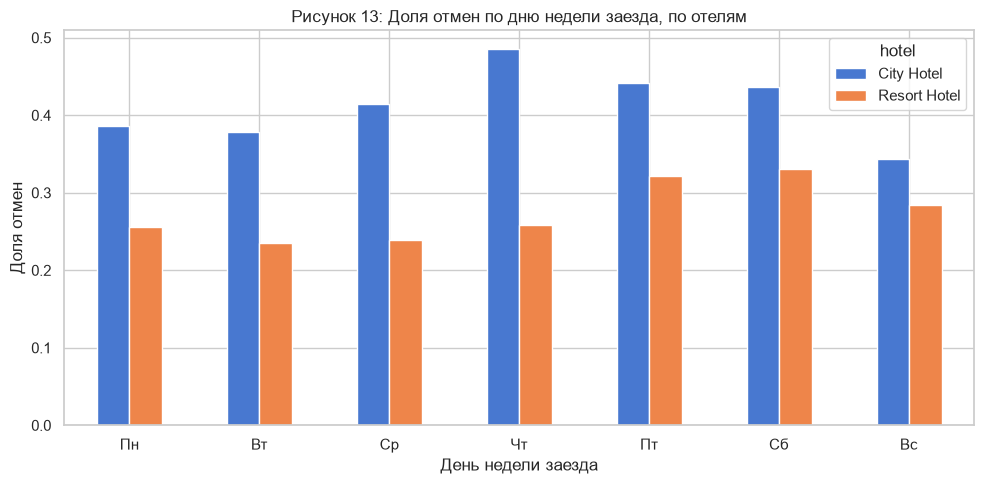

In [54]:
t_df['booking_date'] = t_df['arrival_date'] - pd.to_timedelta(t_df['lead_time'], unit='D')
t_df['arrival_dow'] = t_df['arrival_date'].dt.dayofweek
t_df['booking_dow'] = t_df['booking_date'].dt.dayofweek
t_dow_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

print("Таблица 28: Доля отмен по дню недели")
t_dow_tab = pd.DataFrame({
    'день заезда': t_df.groupby('arrival_dow')['is_canceled'].mean(),
    'день бронирования': t_df.groupby('booking_dow')['is_canceled'].mean()}).T
t_dow_tab.columns = t_dow_names
display(t_dow_tab.round(3))

t_dow_hotel = t_df.groupby(['arrival_dow', 'hotel'])['is_canceled'].mean().unstack()
t_dow_hotel.index = t_dow_names
t_ax = t_dow_hotel.plot(kind='bar', figsize=(10, 5), rot=0)
t_ax.set_xlabel('День недели заезда')
t_ax.set_ylabel('Доля отмен')
t_ax.set_title('Рисунок 13: Доля отмен по дню недели заезда, по отелям')
plt.tight_layout()
plt.show()

### Выводы по дню недели

Отмен больше при заездах в четверг-субботу и меньше в начале недели: от 24.3% во вторник до 30.5% в пятницу. По отелям закономерность разная. У City отмены выше с четверга по субботу (32-33% против 27-29% в остальные дни), у Resort - в пятницу и субботу (27% против 20-21% со вторника по четверг). По дню недели бронирования различия слабее и без выраженной формы: от 26.1% до 31.4%, максимум в воскресенье.

## Длительность проживания

Длительность задана двумя столбцами: ночи в будни и ночи на выходных. Проверяем, как они связаны между собой и с отменами и нужен ли общий признак.

In [55]:
d_wk, d_we = df['stays_in_week_nights'], df['stays_in_weekend_nights']
d_tot = d_wk + d_we
d_y = df['is_canceled']

print("Таблица 29: Корреляции длительности проживания")
display(pd.DataFrame({
    'пара': ['week_nights и weekend_nights', 'week_nights и total', 'weekend_nights и total',
             'week_nights и is_canceled', 'weekend_nights и is_canceled', 'total и is_canceled'],
    'corr': [d_wk.corr(d_we), d_wk.corr(d_tot), d_we.corr(d_tot),
             d_wk.corr(d_y), d_we.corr(d_y), d_tot.corr(d_y)]}).round(3))
print(f"VIF для пары week/weekend при r = {d_wk.corr(d_we):.3f}: {1 / (1 - d_wk.corr(d_we) ** 2):.2f}")

d_bins = pd.cut(d_tot, [-1, 0, 1, 2, 3, 4, 7, 14, 1000],
                labels=['0', '1', '2', '3', '4', '5-7', '8-14', 'более 14'])
d_tab = d_y.groupby(d_bins, observed=True).agg(['size', 'mean']).round(3)
d_tab.columns = ['броней', 'доля отмен']
print("\nТаблица 30: Доля отмен по общей длительности (ночей)")
display(d_tab)

d_has_we = (d_we > 0).map({False: 'только будни', True: 'есть выходные'})
d_has_we[d_tot == 0] = '0 ночей'
print("Таблица 31: Доля отмен в зависимости от наличия выходных в проживании")
display(d_y.groupby(d_has_we).agg(['size', 'mean']).round(3))

Таблица 29: Корреляции длительности проживания


,пара,corr
0,week_nights и weekend_nights,0.499
1,week_nights и total,0.941
2,weekend_nights и total,0.763
3,week_nights и is_canceled,0.025
4,weekend_nights и is_canceled,-0.002
5,total и is_canceled,0.018


VIF для пары week/weekend при r = 0.499: 1.33

Таблица 30: Доля отмен по общей длительности (ночей)


,броней,доля отмен
0,715,0.049
1,21020,0.251
2,27643,0.440
3,27076,0.419
4,17383,0.366
5-7,20296,0.353
8-14,4818,0.340
более 14,439,0.554


Таблица 31: Доля отмен в зависимости от наличия выходных в проживании


,size,mean
stays_in_weekend_nights,,
0 ночей,715,0.049
есть выходные,67392,0.367
только будни,51283,0.380


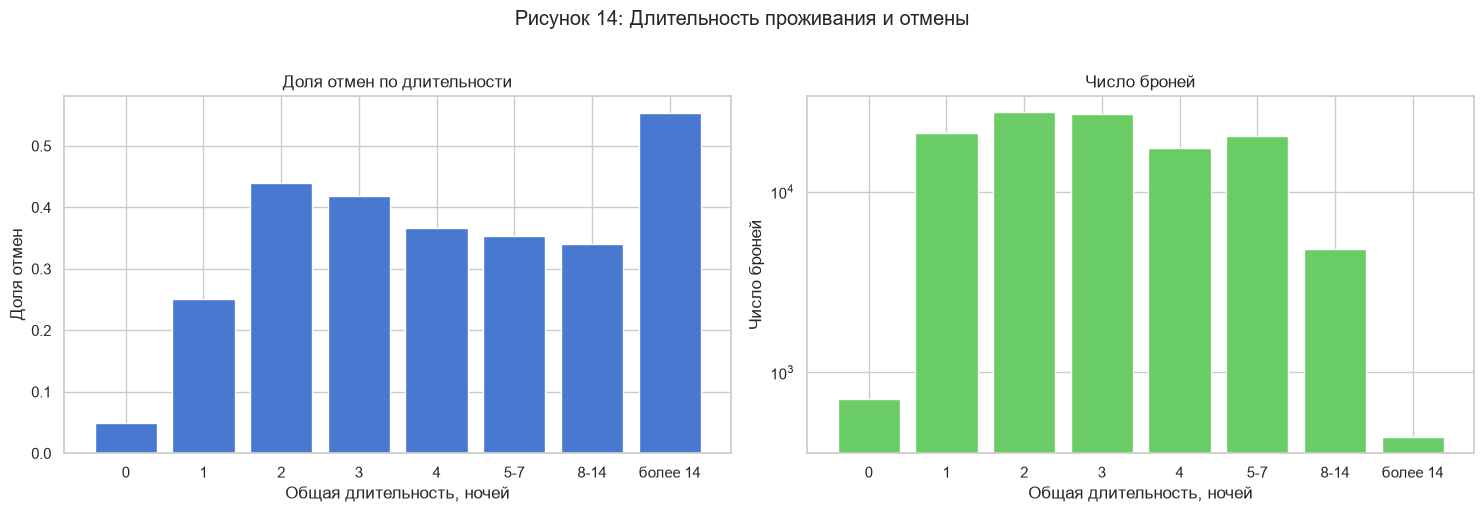

Нулевая длительность по сегментам рынка:


,size,mean
market_segment,,
Aviation,6,0.167
Complementary,23,0.391
Corporate,53,0.038
Direct,136,0.029
Groups,36,0.028
Offline TA/TO,149,0.020
Online TA,312,0.048


Квантили общей длительности: 99% = 14, 99.9% = 25, max = 69


In [56]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(d_tab.index.astype(str), d_tab['доля отмен'], color=sns.color_palette('muted')[0])
axes[0].set_xlabel('Общая длительность, ночей')
axes[0].set_ylabel('Доля отмен')
axes[0].set_title('Доля отмен по длительности')
axes[1].bar(d_tab.index.astype(str), d_tab['броней'], color=sns.color_palette('muted')[2])
axes[1].set_xlabel('Общая длительность, ночей')
axes[1].set_ylabel('Число броней')
axes[1].set_title('Число броней')
axes[1].set_yscale('log')
fig.suptitle('Рисунок 14: Длительность проживания и отмены', y=1.02)
plt.tight_layout()
plt.show()

print("Нулевая длительность по сегментам рынка:")
display(df[d_tot == 0].groupby('market_segment')['is_canceled'].agg(['size', 'mean']).round(3))
print(f"Квантили общей длительности: 99% = {d_tot.quantile(.99):.0f}, 99.9% = {d_tot.quantile(.999):.0f}, max = {d_tot.max()}")

### Выводы по длительности

Ночи в будни и на выходных коррелируют на уровне 0.556: длинное проживание захватывает и будни, и выходные. VIF для такой пары 1.45, то есть мультиколлинеарности, которая мешала бы моделям, нет.

С отменой длительность связана слабо (корреляция общей длительности 0.084), и зависимость не линейна: отмены растут от 18.4% при одной ночи до 30.0% при трёх, дальше почти не меняются (30.5-32.7% для 4-14 ночей) и заметно выше только у проживаний больше 14 ночей (374 брони, 51.1%). Отдельный сигнал выходных дублирует длительность: у проживаний только в будни доля отмен 25.1%, с выходными 29.4%, но выходные чаще входят в длинные проживания (корреляция выходных с общей длительностью 0.786).

Брони с нулевой длительностью (651, 0.75% данных) отменяются в 4.5% случаев и в данных оставлены: ноль ночей физически возможен - размещение на часть дня с заездом и выездом в одну дату. Хвост по длительности не усекается: 99.9% квантиль равен 27 ночам, максимум 69, длинные брони несут сигнал.

Общего признака `total_nights` достаточно вместо двух отдельных: в эксперименте ниже модель с ним качеством не уступает модели с двумя столбцами.

## Проверка вклада временных признаков в модель

Чтобы решение по каждому признаку опиралось на качество модели, сравниваем его вклад на отложенной хронологической выборке. Данные сортируются по восстановленной дате бронирования (дата заезда минус `lead_time`), первые 80% идут в обучение, последние 20% в тест. К базовому набору признаков, известных при бронировании (`lead_time`, `adults`, `previous_cancellations`, `hotel`, `market_segment`, `customer_type`, `distribution_channel`, `is_repeated_guest`), по очереди добавляется каждый временной признак. Используются логистическая регрессия и градиентный бустинг без подбора гиперпараметров. Доверительный интервал (ДИ) разницы ROC-AUC строится бутстрэпом (100 повторов) только по тестовой выборке и не учитывает разброс обучения, поэтому разницу порядка 0.002 считаем шумом. Это проверка признаков, а не итоговые модели.

In [57]:
import warnings
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.metrics import roc_auc_score, average_precision_score

m_df = df.copy()
m_df['arrival_month'] = m_df['arrival_date_month'].map(t_month_map)
m_df['arrival_dt'] = pd.to_datetime(dict(year=m_df['arrival_date_year'], month=m_df['arrival_month'],
                                         day=m_df['arrival_date_day_of_month']))
m_df['booking_dt'] = m_df['arrival_dt'] - pd.to_timedelta(m_df['lead_time'], unit='D')
m_df['arrival_dow'] = m_df['arrival_dt'].dt.dayofweek
m_df['booking_dow'] = m_df['booking_dt'].dt.dayofweek
m_df['total_nights'] = m_df['stays_in_week_nights'] + m_df['stays_in_weekend_nights']
m_df = m_df.sort_values('booking_dt', kind='stable').reset_index(drop=True)

m_cut = int(len(m_df) * 0.8)
m_train, m_test = m_df.iloc[:m_cut], m_df.iloc[m_cut:]
m_y = m_test['is_canceled'].values
print(f"train: {len(m_train)} (доля отмен {m_train['is_canceled'].mean():.3f}), "
      f"test: {len(m_test)} (доля отмен {m_test['is_canceled'].mean():.3f}), "
      f"граница по дате бронирования: {m_test['booking_dt'].min().date()}")

m_base_num = ['lead_time', 'adults', 'previous_cancellations']
m_base_cat = ['hotel', 'market_segment', 'customer_type', 'distribution_channel', 'is_repeated_guest']
m_sets = {
    'базовый набор': ([], []),
    '+ год': (['arrival_date_year'], []),
    '+ месяц': ([], ['arrival_month']),
    '+ номер недели': (['arrival_date_week_number'], []),
    '+ день месяца': (['arrival_date_day_of_month'], []),
    '+ день недели заезда': ([], ['arrival_dow']),
    '+ день недели бронирования': ([], ['booking_dow']),
    '+ week_nights, weekend_nights': (['stays_in_week_nights', 'stays_in_weekend_nights'], []),
    '+ total_nights': (['total_nights'], []),
    '+ месяц, день недели заезда, total_nights': (['total_nights'], ['arrival_month', 'arrival_dow']),
}

def m_fit_predict(kind, num, cat):
    if kind == 'LogReg':
        pre = ColumnTransformer([('n', StandardScaler(), num), ('c', OneHotEncoder(handle_unknown='ignore'), cat)])
        model = make_pipeline(pre, LogisticRegression(max_iter=2000))
    else:
        pre = ColumnTransformer([('n', 'passthrough', num),
                                 ('c', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat)])
        model = make_pipeline(pre, HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=0))
    model.fit(m_train[num + cat], m_train['is_canceled'])
    return model.predict_proba(m_test[num + cat])[:, 1]

m_rng = np.random.default_rng(0)
m_boot = [m_rng.integers(0, len(m_y), len(m_y)) for _ in range(100)]
m_rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for kind in ['LogReg', 'GradBoost']:
        m_pbase = None
        for name, (n_add, c_add) in m_sets.items():
            p = m_fit_predict(kind, m_base_num + n_add, m_base_cat + c_add)
            if name == 'базовый набор':
                m_pbase = p
            d = ([roc_auc_score(m_y[i], p[i]) - roc_auc_score(m_y[i], m_pbase[i]) for i in m_boot]
                 if name != 'базовый набор' else [0])
            m_rows.append({'модель': kind, 'набор': name,
                           'ROC-AUC': roc_auc_score(m_y, p), 'PR-AUC': average_precision_score(m_y, p),
                           'прирост ROC-AUC': roc_auc_score(m_y, p) - roc_auc_score(m_y, m_pbase),
                           'ДИ 95% (низ)': np.percentile(d, 2.5), 'ДИ 95% (верх)': np.percentile(d, 97.5)})
m_res = pd.DataFrame(m_rows)
print("Таблица 32: Вклад временных признаков в качество на хронологическом тесте")
display(m_res.round(4).style.hide(axis='index'))

train: 95512 (доля отмен 0.385), test: 23878 (доля отмен 0.314), граница по дате бронирования: 2017-01-12
Таблица 32: Вклад временных признаков в качество на хронологическом тесте


модель,набор,ROC-AUC,PR-AUC,прирост ROC-AUC,ДИ 95% (низ),ДИ 95% (верх)
LogReg,базовый набор,0.698,0.506,0.000,0.000,0.000
LogReg,+ год,0.697,0.506,-0.001,-0.001,-0.001
LogReg,+ месяц,0.691,0.504,-0.007,-0.009,-0.006
LogReg,+ номер недели,0.695,0.505,-0.003,-0.004,-0.003
LogReg,+ день месяца,0.698,0.507,-0.000,-0.000,0.000
LogReg,+ день недели заезда,0.698,0.512,-0.000,-0.002,0.001
LogReg,+ день недели бронирования,0.697,0.510,-0.001,-0.003,0.001
LogReg,"+ week_nights, weekend_nights",0.698,0.507,-0.000,-0.001,0.000
LogReg,+ total_nights,0.698,0.507,0.000,-0.000,0.001
LogReg,"+ месяц, день недели заезда, total_nights",0.694,0.512,-0.004,-0.006,-0.001


### Результаты проверки

Все эффекты малы: прирост ROC-AUC не превышает 0.005 при базовых 0.688 у логистической регрессии и 0.719 у бустинга.

- **Год** добавляет 0.003 только бустингу (ДИ от 0.001 до 0.005). Прирост объясняется ростом доли отмен по годам, который нельзя перенести на новые периоды.
- **Номер недели и день месяца** качества не меняют (от -0.001 до 0.000).
- **День недели бронирования** вклада не даёт (-0.001 и 0.001).
- **День недели заезда** даёт бустингу 0.002, но интервал включает ноль (от -0.001 до 0.004).
- **Месяц заезда** ухудшает логистическую регрессию (-0.004, ДИ от -0.005 до -0.003) и не помогает бустингу (-0.001). Профиль сезонности у отелей разный, а линейная модель получает один общий месяц.
- **Длительность.** Общий `total_nights` даёт столько же, сколько два исходных столбца: 0.001 и 0.003 против 0.001 и 0.002 у логистической регрессии и бустинга соответственно. Только у бустинга интервал строго выше нуля (от 0.001 до 0.005).
- **Сочетание** месяца, дня недели заезда и `total_nights` лучше всего у бустинга: 0.005 по ROC-AUC (ДИ от 0.002 до 0.009) и 0.449 против 0.439 по PR-AUC. У логистической регрессии то же сочетание чуть хуже базового набора (-0.002, ДИ включает ноль).

### Решения по временным признакам

| Столбец | Решение | Обоснование |
|---|---|---|
| `arrival_date_year` | удалить | три значения, 2015 и 2017 неполные; рост доли отмен (20.3% в 2015, 31.9% в 2017) не переносится на новые периоды, а прирост качества у бустинга (0.003) объясняется именно этим трендом |
| `arrival_date_week_number` | удалить | нумерация нестандартная, "неделя 53" неполная; вклад в качество не отличим от нуля |
| `arrival_date_day_of_month` | удалить | разброс по дням 25.4-29.6% (std 0.013), вклад в качество нулевой |
| `arrival_date_month` | заменить числовым `arrival_month` (1-12) | сезонность выражена у Resort и не сводится к сроку бронирования; способ кодирования выбирается при построении моделей |
| день недели заезда | добавить `arrival_dow` (0 - понедельник, 6 - воскресенье) | различия до 6 пунктов, у отелей разные; вклад небольшой, в сочетании с месяцем и длительностью у бустинга выше шума |
| день недели бронирования | не использовать | различия слабые (26.1-31.4%), вклад в качество не отличим от нуля, признак требует восстановленной даты |
| `stays_in_week_nights`, `stays_in_weekend_nights` | заменить одним `total_nights` | зависимость отмен от длительности насыщается после трёх ночей, одного признака достаточно: качество не ниже, чем с двумя столбцами |

In [58]:
if 'arrival_date_year' in df.columns:
    t_month_num = df['arrival_date_month'].map(t_month_map)
    t_arrival = pd.to_datetime(dict(year=df['arrival_date_year'], month=t_month_num,
                                    day=df['arrival_date_day_of_month']))
    booking_date_split = t_arrival - pd.to_timedelta(df['lead_time'], unit='D')
    df['arrival_month'] = t_month_num
    df['arrival_dow'] = t_arrival.dt.dayofweek
    df['total_nights'] = df['stays_in_week_nights'] + df['stays_in_weekend_nights']
    df = df.drop(columns=['arrival_date_year', 'arrival_date_month', 'arrival_date_week_number',
                          'arrival_date_day_of_month', 'stays_in_week_nights', 'stays_in_weekend_nights'])
    print("Временные признаки применены")
else:
    print("Временные признаки уже применены")
print(f"Размер данных: {df.shape[0]} строк и {df.shape[1]} столбцов")
display(df[['arrival_month', 'arrival_dow', 'total_nights']].describe().round(2).T)

Временные признаки применены
Размер данных: 119390 строк и 33 столбцов


,count,mean,std,min,25%,50%,75%,max
arrival_month,119390.0,6.55,3.09,1.0,4.0,7.0,9.0,12.0
arrival_dow,119390.0,3.00,1.95,0.0,1.0,3.0,5.0,6.0
total_nights,119390.0,3.43,2.56,0.0,2.0,3.0,4.0,69.0


### Результат обработки временных признаков

Шесть исходных столбцов заменены тремя: `arrival_month`, `arrival_dow` и `total_nights`.

Столбцы `arrival_date` и `booking_date` были добавлены в `df` раньше, в разделе про утечки. Признаками они не являются. `arrival_date` исключается из набора: он содержит год, удалённый выше как непереносимый на новые периоды. `booking_date` остаётся столбцом итоговой таблицы, но в список признаков не входит - она нужна для хронологического разбиения выборки, и восстановить её из оставшихся столбцов невозможно.

**Применение на следующем этапе.** Способ кодирования `arrival_month` (категориальный или циклический) выбирается при построении моделей, так как линейная модель плохо использует его как число.

# Формирование итогового набора признаков

In [59]:
LEAKAGE_COLUMNS = [
    'reservation_status',
    'reservation_status_date',
    'assigned_room_type',
    'deposit_type',
    'required_car_parking_spaces',
    'booking_changes',
]

SERVICE_COLUMNS = [
    'has_deposit',    # Производный от deposit_type, исключается вместе с ним
    'lead_time_bin',  # создан для таблицы по интервалам, дублирует lead_time
    'arrival_date'    # содержит год, удалённый по решению раздела о времени
]

df_clean = df.copy()
print(f"Исходный размер: {df_clean.shape}")

df_clean = df_clean.drop(columns=LEAKAGE_COLUMNS + SERVICE_COLUMNS)
print(f"После удаления признаков с утечкой и служебных столбцов: {df_clean.shape}")

Исходный размер: (119390, 33)
После удаления признаков с утечкой и служебных столбцов: (119390, 24)


In [60]:
zero_guests_mask = (
    (df_clean['adults'] == 0) &
    (df_clean['children'] == 0) &
    (df_clean['babies'] == 0)
)

print(f"Строк к удалению (ноль гостей): {zero_guests_mask.sum()}")

df_clean = df_clean[~zero_guests_mask]
print(f"После удаления строк с нулём гостей: {df_clean.shape}")

Строк к удалению (ноль гостей): 180
После удаления строк с нулём гостей: (119210, 24)


In [61]:
invalid_adr_mask = (df_clean['adr'] < 0) | (df_clean['adr'] > 1000)

print("Удаляемые записи:")
print(df_clean.loc[invalid_adr_mask,
                   ['adr', 'total_nights', 'adults', 'hotel', 'is_canceled']]
      .to_string(index=False))
df_clean = df_clean[~invalid_adr_mask]

p99 = df_clean['adr'].quantile(0.99)
print(f"\nadr после очистки: минимум {df_clean['adr'].min():.2f}, "
      f"медиана {df_clean['adr'].median():.2f}, p99 {p99:.2f}, "
      f"максимум {df_clean['adr'].max():.0f}")
print(f"Значений выше p99: {(df_clean['adr'] > p99).sum()} "
      f"({(df_clean['adr'] > p99).mean():.2%})")
print(f"Нулевых: {(df_clean['adr'] == 0).sum()} ({(df_clean['adr'] == 0).mean():.2%}), "
      f"доля отмен в них {df_clean.loc[df_clean['adr'] == 0, 'is_canceled'].mean():.1%}")

Удаляемые записи:
    adr  total_nights  adults        hotel  is_canceled
  -6.38            10       2 Resort Hotel            0
5400.00             1       2   City Hotel            1

adr после очистки: минимум 0.00, медиана 94.95, p99 252.00, максимум 510
Значений выше p99: 1167 (0.98%)
Нулевых: 1810 (1.52%), доля отмен в них 10.4%


### Решение по признаку adr

**Удалённые записи.** Из набора удалены две записи, по разным основаниям.

Первая содержит отрицательную цену. В момент подтверждения брони отрицательное значение невозможно, а восстановить истинное по данным нельзя. Замена нулём отклонена: ноль в этих данных не нейтрален, он образует отдельную группу с долей отмен 10.3% против 27.5% в среднем, и ошибочная запись получила бы чужой смысл.

Вторая содержит значение 5 400 при медиане 98.2. Запись удалена не как крайнее значение, а как изолированное: ближайшее значение сверху составляет 510, то есть наблюдение отделено от распределения более чем десятикратным разрывом. Любой порог внутри этого разрыва даёт один и тот же результат, поэтому выбор границы на итог не влияет.

**Верхний хвост не усекается.** Решение принято по трём основаниям.

Крайние значения правдоподобны. Верхние значения идут вплотную друг к другу: 510, 508, 451.5, 450. Разрывов в распределении до самого верха нет, поэтому граница усечения была бы выбрана произвольно. Усечение по p99 изменило бы 873 значения, то есть 1% данных.

Усечение не влияет на выводы. Корреляция `adr` с целевой переменной на итоговом наборе составляет 0.133 без усечения и 0.135 с усечением, среднее меняется со 106.46 на 106.13. Изменение реальных значений такой ценой не окупается.

Дорогой сегмент нужен для анализа. Карточка темы предусматривает разбор ошибок модели по ценовым сегментам, а усечение убирает именно верхний сегмент.

Различие между двумя решениями принципиально: удаляется наблюдение, оторванное от распределения разрывом, сохраняется непрерывный хвост. Критерий здесь не величина значения, а наличие разрыва.

**Нулевые значения сохраняются.** Их 1 643, то есть 1.88% набора, доля отмен в них 10.3% против 27.5% в среднем. Устойчивое отличие от средней доли означает, что ноль ведёт себя как самостоятельная категория, а не как незаполненное поле: случайный пропуск не давал бы разрыва такого размера. Признак несёт сигнал и сохраняется.

**Применение на следующем этапе.** Порог обработки `adr`, если он понадобится при построении моделей, рассчитывается на обучающей выборке и применяется к тестовой. Расчёт на всех данных дал бы утечку информации из теста в обучение.


In [62]:
# days_in_waiting_list: 99% нулей, информативен сам факт попадания в лист ожидания
df_clean['was_in_waiting_list'] = (df_clean['days_in_waiting_list'] > 0).astype(int)
df_clean = df_clean.drop(columns=['days_in_waiting_list'])

print(df_clean.groupby('was_in_waiting_list')['is_canceled']
      .agg(Броней='size', Доля_отмен='mean').round(3).to_string())

print(f"\nИтоговый набор: {df_clean.shape[0]:,} строк x {df_clean.shape[1]} столбцов")
print(f"Целевая переменная: is_canceled, доля отмен {df_clean['is_canceled'].mean():.2%}")
print(f"Пропусков: {df_clean.isna().sum().sum()}\n")

print("Состав набора:")
for n, (col, dtype) in enumerate(df_clean.dtypes.items(), 1):
    print(f"{n:>3}. {col:<32} {dtype}")

                     Броней  Доля_отмен
was_in_waiting_list                    
0                    115515       0.362
1                      3693       0.639

Итоговый набор: 119,208 строк x 24 столбцов
Целевая переменная: is_canceled, доля отмен 37.08%
Пропусков: 0

Состав набора:
  1. hotel                            str
  2. is_canceled                      int64
  3. lead_time                        int64
  4. adults                           int64
  5. children                         int64
  6. babies                           int64
  7. meal                             str
  8. country                          str
  9. market_segment                   str
 10. distribution_channel             str
 11. is_repeated_guest                int64
 12. previous_cancellations           int64
 13. previous_bookings_not_canceled   int64
 14. reserved_room_type               str
 15. agent                            str
 16. customer_type                    str
 17. adr                   

In [63]:
df_clean.to_csv('hotels.csv', index=False)

# Реестр утечек данных

Критерий пригодности признака: значение известно и зафиксировано в момент подтверждения брони. Согласно спецификации проекта, именно в этот момент выполняется скоринг: сервис оценивает риск отмены сразу после подтверждения брони и имеет доступ только к полям, доступным в этот момент.

Все приведённые ниже числа посчитаны на данных после удаления дубликатов (87 396 броней).

## Признаки, исключённые из модели

| Признак | Тип утечки |
| :-- | :-- |
| `reservation_status` | Прямая утечка таргета |
| `reservation_status_date` | Постфактум-информация |
| `assigned_room_type` | Постфактум-информация |
| `deposit_type` | Требует проверки, см. п. 4 |
| `required_car_parking_spaces` | Постфактум-заполнение |
| `booking_changes` | Постфактум-накопление |

### Обоснования

1. `reservation_status`. Кросс-таблица с целевой переменной показывает точное совпадение: `is_canceled == 1` соответствует статусам `Canceled` (23 011 записей) и `No-Show` (1 014 записей), `is_canceled == 0` соответствует `Check-Out` (63 371 запись). Признак является другой формой записи таргета.

2. `reservation_status_date`. Проверка хронологии показала: ни одна запись не имеет даты изменения статуса раньше даты создания брони, а у 62 726 записей дата изменения статуса следует после даты заезда. Значение становится известным только после исхода.

3. `assigned_room_type`. Сопоставление с `reserved_room_type` показало расхождения в 15.00% бронирований (13 109 записей): фактический номер определяется при заселении. Модель не может знать это значение в момент подтверждения брони.

4. `deposit_type`. Экономическая логика предполагает, что невозвратный депозит снижает склонность к отмене, однако доля отмен в категории `Non Refund` составляет 94.7%. Такие брони имеют существенно больший срок до заезда (медиана `lead_time` 188.5 дня против 49 по всем броням) и практически нулевое число изменений (среднее 0.09). Это согласуется с гипотезой о присвоении статуса системой после факта отмены, но прямого доказательства утечки данные не дают. Решение о включении признака принимается на следующем чекпойнте по результатам сравнения моделей с признаком и без него.

5. `required_car_parking_spaces`. Абсолютный ноль отмен на выборке из 7 313 броней не объясняется поведением: даже при вероятности отмены 1% шанс наблюдать ноль отмен составляет порядка 10⁻³². Все бронирования с запросом парковки имеют статус `Check-Out`, следовательно, значение фиксируется при фактическом заселении.

6. `booking_changes`. Ненулевые значения встречаются у 2 457 отменённых броней, что доказывает фиксацию изменений в течение жизни брони, после подтверждения. В момент скоринга новой брони значение признака всегда равно нулю, поэтому обучение на финальных значениях создаёт рассогласование между обучением и инференсом. Наблюдаемое снижение доли отмен при ненулевых изменениях (15.5% против 30.2% при нуле) является survival bias: брони, дожившие до заезда, успевают накопить изменения.

## Преобразования, не связанные с утечками

| Исходные столбцы | Заменены на | Причина |
| :-- | :-- | :-- |
| `company` | `has_company` | 93.98% пропусков, учиться по идентификаторам невозможно, факт корпоративной брони значим |
| `days_in_waiting_list` | `was_in_waiting_list` | 99% нулей, информативен сам факт попадания в лист ожидания |
| `deposit_type` | `has_deposit` | признак исключён из набора вместе с исходным столбцом до решения по п. 4 |
| `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month` | `arrival_month`, `arrival_dow` | год и номер недели не переносятся на новые периоды, день месяца вклада не даёт |
| `stays_in_week_nights`, `stays_in_weekend_nights` | `total_nights` | отдельный сигнал выходных дублирует длительность, качество не ниже |

Итог: из 32 исходных столбцов 6 исключены как содержащие утечку или требующие проверки, 3 заменены бинарными признаками, 6 временных столбцов заменены тремя. Остальные пригодны для моделирования.

# Выводы по результатам разведочного анализа

## Полные повторы

В исходных данных 119 390 строк и 87 396 уникальных комбинаций значений всех 32 исходных столбцов. При удалении полных повторов с сохранением первого экземпляра каждой комбинации было бы удалено 31 994 строки, или 26.80%. Это число повторных экземпляров, а не всех строк, входящих в повторяющиеся группы.

Происхождение повторов не установлено. На сегменты `Groups` и `Offline TA/TO` приходится 78.8% повторных экземпляров, максимальная группа содержит 180 одинаковых строк. Однако эти наблюдения не подтверждают, что строки относятся к одной заявке на несколько номеров. Без идентификатора бронирования или групповой заявки нельзя отличить технические повторы от самостоятельных броней с одинаковыми параметрами.

В основном `df` все строки сохраняются. Влияние удаления полных повторов проверено отдельно, без изменения основного набора. Сравнение выполнено на исходных данных, до обработки пропусков и выбросов.

При удалении повторов общая доля отмен меняется с 37.0% до 27.5%, а в сегменте `Groups` — с 61.1% до 27.0%. Число наблюдений категории `Non Refund` сокращается с 14 587 до 1 038, а её доля в наборе — примерно с 12.2% до 1.2%. Эти проценты характеризуют распространённость категории, а не долю отмен внутри неё.

Корреляция `adr` с `is_canceled` меняется с 0.048 до 0.128, а корреляция `lead_time` — с 0.293 до 0.185. Знаки этих связей сохраняются, но их величины чувствительны к решению о повторах.

Таким образом, дедупликация существенно меняет состав выборки и описательные показатели. Это не доказывает корректность удаления и не позволяет объявить связи в полном наборе артефактом. Сохранение возможных технических повторов также остаётся ограничением данных. Устойчивость качества моделей к решению о повторах отдельно не установлена.

## Число номеров в заявке

`rooms_in_booking` не включается в анализ и итоговый набор признаков. Доступные поля не позволяют определить число номеров в заявке независимо от её исхода.

Для получения признака необходим источник числа номеров на момент подтверждения брони: соответствующее поле заявки либо история её состава с идентификаторами номерных позиций и временем изменений.

Подсчёт строк по идентификатору заявки допустим только при подтверждении, что каждая строка соответствует одному номеру, технические повторы отсутствуют, а состав заявки отражает состояние на момент прогноза.

## Пропуски и обработка данных

Пропуски сосредоточены в четырёх исходных столбцах: `children`, `country`, `agent` и `company`. Для их обработки приняты следующие решения:

- `children` заполняется нулём и приводится к целочисленному типу. Заполнение нулём является допущением, а не подтверждённым отсутствием детей.
- `country` получает отдельную категорию `Unknown`.
- `agent` переводится в строковый тип; отсутствие указанного идентификатора обозначается категорией `No agent`. Эта метка сама по себе не доказывает отсутствие посредника.
- `company` заменяется бинарным индикатором `has_company`, отражающим наличие указанного идентификатора компании.

Обработка пропусков не предусматривает удаления строк. Размер набора, число оставшихся пропусков и доля отмен на этом этапе приводятся в итоговой таблице предобработки.

Очистка аномалий является отдельным этапом. Решения по отрицательным и экстремальным значениям `adr`, а также записям с нулевым числом гостей должны быть согласованы с кодом формирования итогового набора. Для каждой статистики необходимо указывать, рассчитана ли она до или после этой очистки.

## Целевая переменная

`is_canceled` объединяет отмену бронирования и неявку гостя. При интерпретации прогноза эти исходы необходимо учитывать совместно.

`reservation_status` позволяет проверить согласованность целевой переменной с итоговым статусом, но не используется как предиктор. `reservation_status_date` описывает дату последнего статуса и также не включается в признаки модели.

Доля отмен зависит от этапа обработки и решения о повторах. Значение 37.0% относится к полному исходному набору, а 27.5% — к альтернативному сценарию после удаления полных повторов. Ни одно из этих значений не следует автоматически переносить на обучающую, валидационную или тестовую выборку.

## Доступность признаков и утечки

Доступность признаков оценивается относительно момента подтверждения брони. Наличие столбца в выгрузке не подтверждает, что его значение было известно в этот момент.

Для `adr`, `assigned_room_type`, `deposit_type`, `booking_changes`, `required_car_parking_spaces` и `total_of_special_requests` требуется зафиксировать момент формирования значения и источник, который это подтверждает. До завершения такой проверки их допустимость в модели не считается установленной.

Отсутствие отмен среди наблюдений с парковкой само по себе не доказывает, что поле заполняется при заселении. Высокая доля отмен в категории `Non Refund` также не устанавливает момент присвоения категории или причину наблюдаемой связи.

Сравнение качества моделей с признаком и без него показывает его вклад в прогноз на выбранной проверке, но не подтверждает отсутствие утечки.

## Связи признаков с отменой

Описательный анализ рассматривает связи отмены с параметрами бронирования, каналом продаж, историей гостя, ценой и длительностью проживания.

Различия долей отмен между группами не устанавливают причинную связь и сами по себе не определяют предсказательную силу признаков. Утверждения о наиболее сильных предикторах требуют отдельной проверки на корректной временной валидации.

Результаты чувствительны к составу выборки. После сохранения полных повторов все групповые статистики, корреляции и сопровождающие их выводы должны соответствовать этому решению.

Основные сравнения долей отмен сопровождаются размерами групп, числом отмен и интервалами неопределённости. При интерпретации интервалов необходимо учитывать возможную зависимость наблюдений: неизвестная природа повторов не позволяет гарантировать независимость строк.

## Временные признаки и проверка моделей

Дата оформления бронирования восстанавливается как разность даты заезда и `lead_time`. Она используется для построения календарного разбиения, однако одна сортировка по этой дате не обеспечивает корректность проверки.

В обучение на выбранной календарной границе должны попадать только наблюдения, исход которых уже доступен к этой границе. Для этого отдельно определяется и обосновывается момент доступности целевой переменной.

Выбор временных признаков и других вариантов подготовки данных выполняется на временной валидации. Отдельный финальный тест сохраняется для оценки выбранного решения и не используется для отбора признаков.

Месяц и день недели заезда, а также общая длительность проживания рассматриваются как варианты представления временной информации. Окончательные решения об их включении принимаются по результатам исправленной временной проверки.

При интерпретации различий по годам и месяцам учитывается неполное покрытие календарных периодов. Различия между периодами сами по себе не позволяют отделить сезонность от изменения состава броней и общего уровня отмен.

## Границы применимости

Данные описывают два португальских отеля за период 2015–2017 годов. Переносимость результатов на другие отели и периоды не установлена.

Высокая или близкая к 50% доля отмен внутри сегмента не означает, что качество прогноза в нём близко к случайному. Для такого вывода необходимо отдельно рассчитать метрики модели внутри сегмента и учесть размер проверочной группы.

Неопределённое происхождение полных повторов и отсутствие подтверждённого размера заявки остаются ограничениями набора. Дополнительное ограничение связано с механизмом отбора наблюдений: выборка ограничена периодом заездов, поэтому состав броней по дате оформления и горизонту бронирования требует отдельного учёта при временной проверке.

## Применение результатов на следующем этапе

| Решение или ограничение | Применение |
|---|---|
| Полные повторы сохранены | Основной анализ выполняется без дедупликации; альтернативный сценарий используется для проверки чувствительности |
| `rooms_in_booking` не включён в набор | Получение признака требует независимого источника числа номеров на момент подтверждения брони |
| Итоговые статусы описывают исход | `reservation_status` и `reservation_status_date` не используются как предикторы |
| Доступность спорных признаков требует подтверждения | Для каждого признака фиксируются момент доступности и подтверждающий источник |
| Пропуски категориальных признаков обозначены явно | Категории `Unknown` и `No agent` сохраняются при подготовке модельного набора |
| `company` заменён на `has_company` | Используется индикатор наличия указанного идентификатора компании |
| Очистка аномалий выделена в отдельный этап | Решения по составу гостей и `adr` согласуются с кодом и итоговым размером набора |
| Статистики зависят от этапа обработки | Для показателей указывается состав данных, на котором они рассчитаны |
| Сравнения долей требуют оценки неопределённости | Приводятся размеры групп, число отмен и интервалы с указанием допущений |
| Временная проверка учитывает доступность исходов | Обучение использует только исходы, известные к календарной границе |
| Отбор признаков отделён от финальной оценки | Решения принимаются на временной валидации; финальный тест используется отдельно |
| Качество внутри сегментов не установлено по долям отмен | Метрики модели рассчитываются отдельно для выделенных сегментов |

Окончательные выводы о качестве модели, полезности признаков и различиях между сегментами формулируются после согласования реестра доступности признаков, временной проверки и результатов на едином наборе данных.